# 03 · Análisis Exploratorio de Datos (EDA) — Savia Salud EPS

**Objetivo:** Entender la distribución del dataset de entrenamiento, identificar patrones discriminadores por clase y documentar hallazgos para la tesis.

**Dataset:** `data/processed/20260304_dataset_entrenamiento.parquet`  
**Clases:** 0=Auditada · 1=Glosada · 2=Devuelta  
**Paleta:** verde=Auditada · naranja=Glosada · rojo=Devuelta

## Análisis cubiertos
1. Distribución de clases vs distribución real en BD
2. `valor_factura` por clase (boxplot log)
3. `dias_hasta_radicacion` por clase
4. `tasa_glosa_nit` vs `tasa_devolucion_nit` (scatter por clase)
5. Heatmap de correlaciones numéricas
6. Top-20 NITs con mayor tasa de glosa
7. Serie temporal por mes y clase
8. Outliers y completitud de datos
9. Features discriminadoras clave
10. Variables categóricas
11. Baseline sistema IA Savia (`ejecucion_glosa_aut_ia`)
12. Resumen de hallazgos para tesis

In [1]:
# Celda 1 — Configuración e imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# ── Configuración global de gráficos ──────────────────────────
plt.rcParams.update({
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'figure.facecolor': 'white',
    'axes.facecolor': '#f8f9fa',
    'axes.grid': True,
    'grid.alpha': 0.4,
})

# ── Paleta de colores: verde=Auditada, naranja=Glosada, rojo=Devuelta
PALETTE = {0: '#27ae60', 1: '#e67e22', 2: '#e74c3c'}
LABELS  = {0: 'Auditada', 1: 'Glosada', 2: 'Devuelta'}
COLORS  = [PALETTE[k] for k in sorted(PALETTE)]

# ── Rutas ──────────────────────────────────────────────────────
DATA_FILE   = Path(r'D:\Users\jcardonr\Documents\eafit\Codigo\data\processed\20260304_dataset_entrenamiento.parquet')
FIGURES_DIR = Path(r'D:\Users\jcardonr\Documents\eafit\Codigo\reports\figures')
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name: str):
    """Guarda la figura activa en reports/figures/ a 300 dpi."""
    path = FIGURES_DIR / name
    plt.savefig(path, dpi=300, bbox_inches='tight', facecolor='white')
    print(f'  💾 Guardado: {path.name}')

print('✅ Configuración lista')
print(f'   Figuras → {FIGURES_DIR}')

✅ Configuración lista
   Figuras → D:\Users\jcardonr\Documents\eafit\Codigo\reports\figures


In [2]:
# Celda 2 — Cargar dataset y estadísticas básicas
df = pd.read_parquet(DATA_FILE)

print('=' * 60)
print('DATASET DE ENTRENAMIENTO — RESUMEN GENERAL')
print('=' * 60)
print(f'Filas:    {len(df):,}')
print(f'Columnas: {len(df.columns)}')
print(f'Tamaño:   {DATA_FILE.stat().st_size / 1024 / 1024:.1f} MB')

print('\nTipos de datos:')
type_summary = df.dtypes.value_counts()
for dtype, count in type_summary.items():
    print(f'  {str(dtype):<15}: {count} columnas')

print('\nDistribución TARGET:')
for cls, cnt in df['target'].value_counts().sort_index().items():
    print(f'  Clase {cls} ({LABELS[cls]:8s}): {cnt:>8,}  ({cnt/len(df)*100:.1f}%)')

print('\nColumnas numéricas — estadísticas:')
display(df.select_dtypes(include='number').describe().T.round(2))

DATASET DE ENTRENAMIENTO — RESUMEN GENERAL
Filas:    728,289
Columnas: 39
Tamaño:   26.5 MB

Tipos de datos:
  float64        : 20 columnas
  int64          : 8 columnas
  object         : 6 columnas
  int32          : 3 columnas
  datetime64[ns] : 2 columnas

Distribución TARGET:
  Clase 0 (Auditada):  188,576  (25.9%)
  Clase 1 (Glosada ):  400,000  (54.9%)
  Clase 2 (Devuelta):  139,713  (19.2%)

Columnas numéricas — estadísticas:


,count,mean,std,min,25%,50%,75%,max
factura_id,728289.0,21110654.80,1.152737e+06,19451372.0,20169645.00,20912526.00,21852229.00,2.415020e+07
target,728289.0,0.93,6.700000e-01,0.0,0.00,1.00,1.00,2.000000e+00
valor_factura,728289.0,3447007.26,1.764591e+07,0.0,70000.00,152200.00,967320.00,3.484972e+08
valor_copago,728289.0,11349.49,2.034145e+05,0.0,0.00,0.00,0.00,4.726211e+07
valor_cuota_moderadora,728289.0,8887.50,3.206901e+05,0.0,0.00,0.00,0.00,5.312412e+07
dias_hasta_radicacion,728289.0,43.49,6.972000e+01,0.0,9.00,20.00,42.00,3.650000e+02
origen_factura,728289.0,3.00,0.000000e+00,3.0,3.00,3.00,3.00,3.000000e+00
mes_radicacion,728289.0,6.55,3.200000e+00,1.0,4.00,6.00,9.00,1.200000e+01
trimestre_radicacion,728289.0,2.55,1.040000e+00,1.0,2.00,2.00,3.00,4.000000e+00
anio_radicacion,728289.0,2024.43,5.500000e-01,2024.0,2024.00,2024.00,2025.00,2.026000e+03


  💾 Guardado: eda_01_distribucion_clases.png


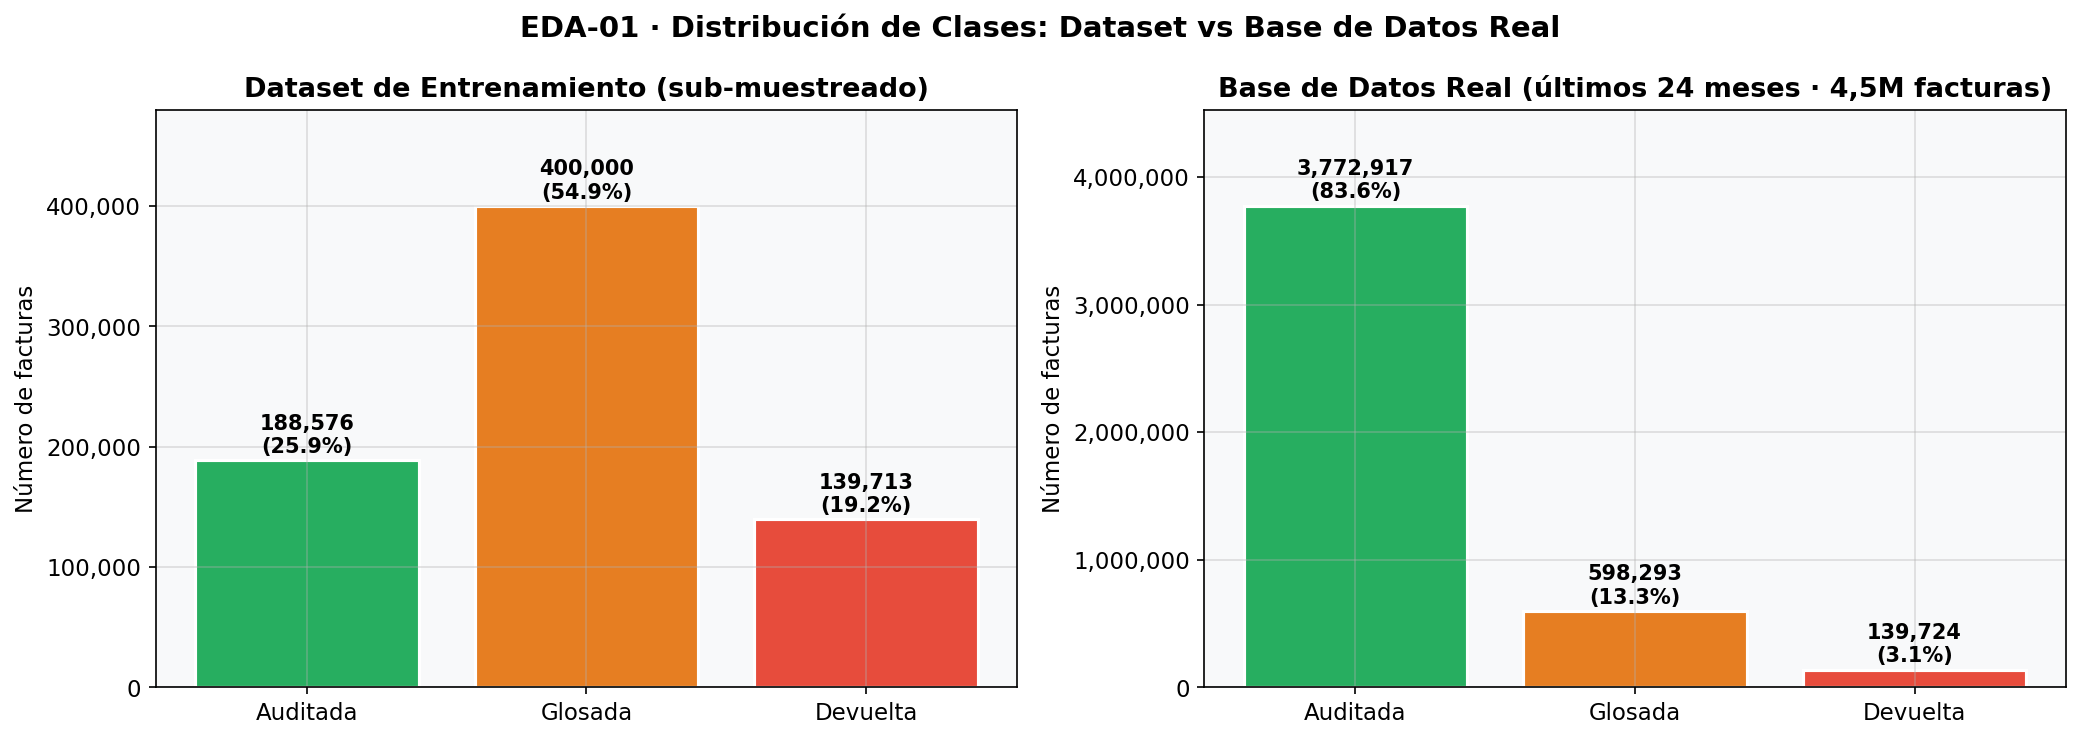


📌 HALLAZGO: El muestreo reduce el desbalance 83%/13%/3% → 26%/55%/19%.
   Documentar en tesis como estrategia de balanceo de clases en etapa de extracción.


In [3]:
# Celda 3 — EDA-01: Distribución de clases (dataset vs BD real)

# Distribución real en BD (últimos 24 meses — confirmada en Fase 1B)
DIST_BD_REAL = {0: 3_772_917, 1: 598_293, 2: 139_724}
total_bd = sum(DIST_BD_REAL.values())

dist_dataset = df['target'].value_counts().sort_index()
total_dataset = len(df)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('EDA-01 · Distribución de Clases: Dataset vs Base de Datos Real', fontsize=14, fontweight='bold')

# Panel A: Dataset de entrenamiento
ax = axes[0]
bars = ax.bar(
    [LABELS[i] for i in range(3)],
    [dist_dataset[i] for i in range(3)],
    color=COLORS, edgecolor='white', linewidth=1.5
)
for bar, cls in zip(bars, range(3)):
    cnt = dist_dataset[cls]
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 3000,
            f'{cnt:,}\n({cnt/total_dataset*100:.1f}%)', ha='center', va='bottom', fontsize=10, fontweight='bold')
ax.set_title('Dataset de Entrenamiento (sub-muestreado)')
ax.set_ylabel('Número de facturas')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax.set_ylim(0, max(dist_dataset) * 1.2)

# Panel B: BD real
ax2 = axes[1]
bars2 = ax2.bar(
    [LABELS[i] for i in range(3)],
    [DIST_BD_REAL[i] for i in range(3)],
    color=COLORS, edgecolor='white', linewidth=1.5
)
for bar, cls in zip(bars2, range(3)):
    cnt = DIST_BD_REAL[cls]
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 30000,
             f'{cnt:,}\n({cnt/total_bd*100:.1f}%)', ha='center', va='bottom', fontsize=10, fontweight='bold')
ax2.set_title('Base de Datos Real (últimos 24 meses · 4,5M facturas)')
ax2.set_ylabel('Número de facturas')
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax2.set_ylim(0, max(DIST_BD_REAL.values()) * 1.2)

plt.tight_layout()
save_fig('eda_01_distribucion_clases.png')
plt.show()

print('\n📌 HALLAZGO: El muestreo reduce el desbalance 83%/13%/3% → 26%/55%/19%.')
print('   Documentar en tesis como estrategia de balanceo de clases en etapa de extracción.')

  💾 Guardado: eda_02_valor_factura.png


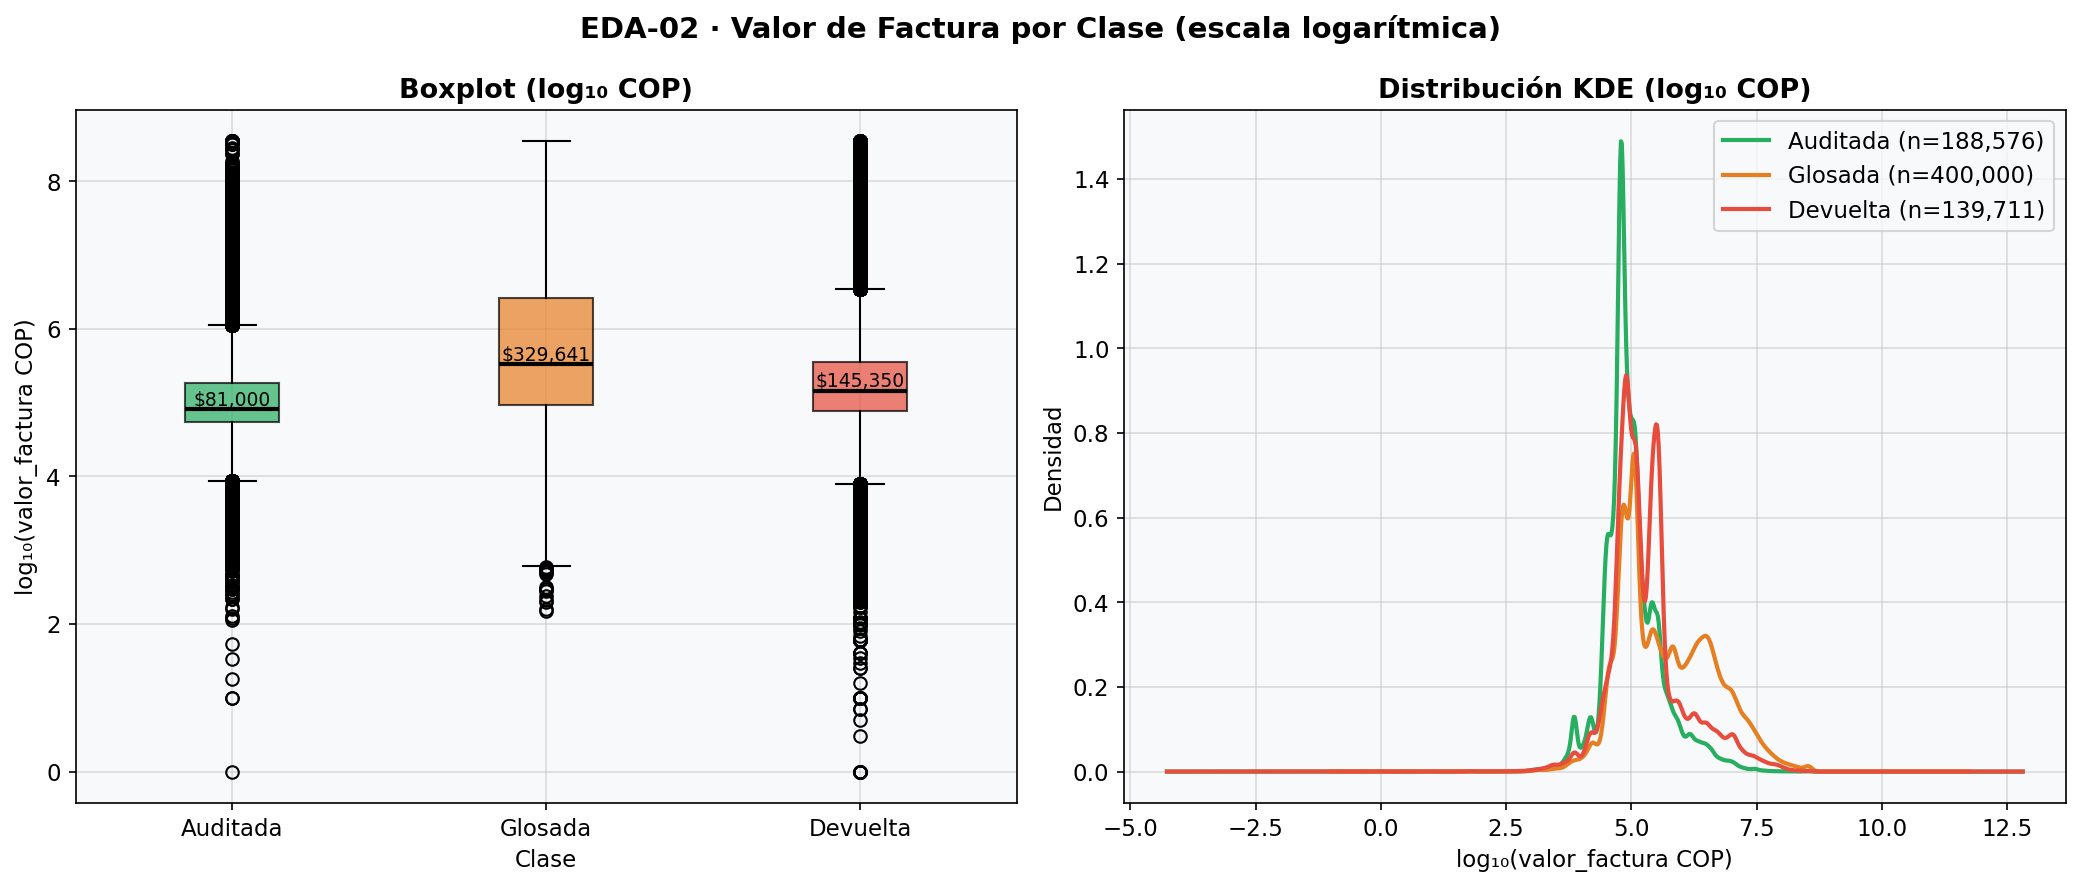


Mediana de valor_factura por clase:
  Clase 0 (Auditada): $         81,000 COP
  Clase 1 (Glosada ): $        329,641 COP
  Clase 2 (Devuelta): $        145,350 COP


In [4]:
# Celda 4 — EDA-02: valor_factura por clase (boxplot + violinplot log-scale)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('EDA-02 · Valor de Factura por Clase (escala logarítmica)', fontsize=14, fontweight='bold')

df_plot = df[df['valor_factura'] > 0].copy()
df_plot['log_valor'] = np.log10(df_plot['valor_factura'])
df_plot['clase_label'] = df_plot['target'].map(LABELS)

# Boxplot
ax = axes[0]
data_by_class = [df_plot[df_plot['target'] == cls]['log_valor'].values for cls in range(3)]
bp = ax.boxplot(data_by_class, labels=[LABELS[i] for i in range(3)], patch_artist=True,
                medianprops={'color': 'black', 'linewidth': 2})
for patch, color in zip(bp['boxes'], COLORS):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax.set_title('Boxplot (log₁₀ COP)')
ax.set_ylabel('log₁₀(valor_factura COP)')
ax.set_xlabel('Clase')
# Anotaciones de mediana
for i, cls in enumerate(range(3)):
    med = np.median(data_by_class[i])
    ax.text(i+1, med + 0.05, f'${10**med:,.0f}', ha='center', fontsize=9, color='black')

# KDE por clase
ax2 = axes[1]
for cls in range(3):
    subset = df_plot[df_plot['target'] == cls]['log_valor']
    subset.plot.kde(ax=ax2, label=f'{LABELS[cls]} (n={len(subset):,})',
                    color=PALETTE[cls], linewidth=2)
ax2.set_title('Distribución KDE (log₁₀ COP)')
ax2.set_xlabel('log₁₀(valor_factura COP)')
ax2.set_ylabel('Densidad')
ax2.legend()

plt.tight_layout()
save_fig('eda_02_valor_factura.png')
plt.show()

# Tabla de medianas
print('\nMediana de valor_factura por clase:')
for cls in range(3):
    med = df_plot[df_plot['target'] == cls]['valor_factura'].median()
    print(f'  Clase {cls} ({LABELS[cls]:8s}): ${med:>15,.0f} COP')

  💾 Guardado: eda_03_dias_radicacion.png


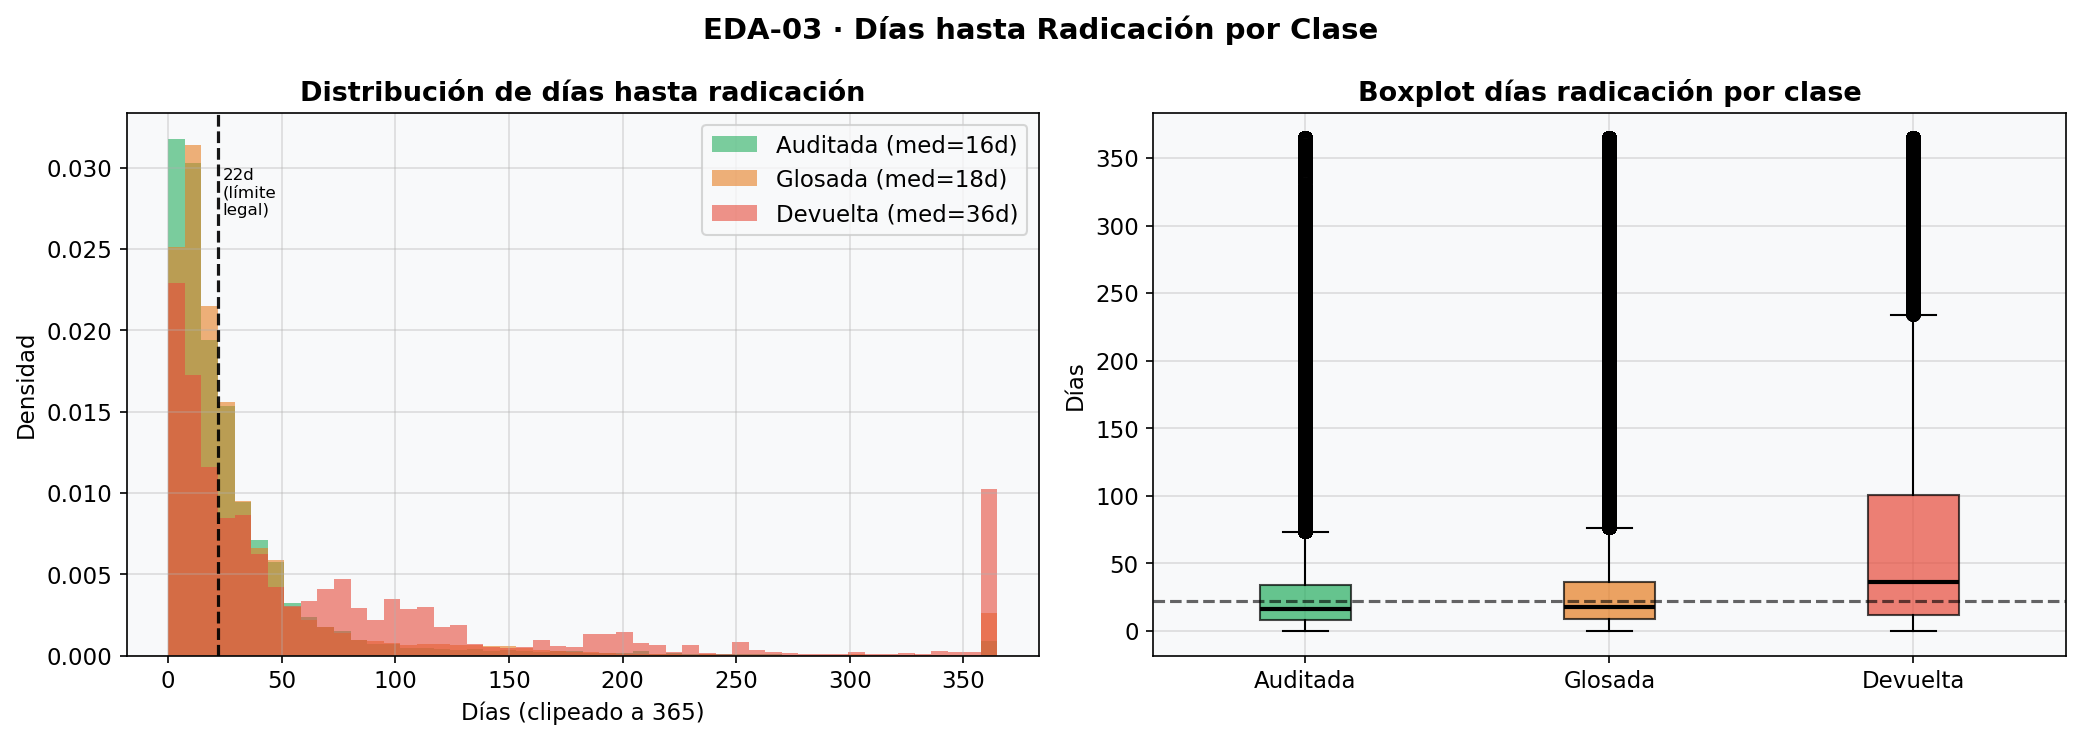


% facturas con radicación extemporánea (>22 días) por clase:
  Clase 0 (Auditada): 38.9%  (mediana=16d)
  Clase 1 (Glosada ): 41.3%  (mediana=18d)
  Clase 2 (Devuelta): 61.2%  (mediana=36d)


In [5]:
# Celda 5 — EDA-03: dias_hasta_radicacion por clase

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('EDA-03 · Días hasta Radicación por Clase', fontsize=14, fontweight='bold')

# Histograma superpuesto
ax = axes[0]
for cls in range(3):
    subset = df[df['target'] == cls]['dias_hasta_radicacion']
    ax.hist(subset, bins=50, alpha=0.6, label=f'{LABELS[cls]} (med={subset.median():.0f}d)',
            color=PALETTE[cls], density=True)
ax.set_title('Distribución de días hasta radicación')
ax.set_xlabel('Días (clipeado a 365)')
ax.set_ylabel('Densidad')
ax.legend()
ax.axvline(22, color='black', linestyle='--', alpha=0.7, label='22 días (límite legal)')
ax.axvline(22, color='black', linestyle='--', alpha=0.7)
ax.text(24, ax.get_ylim()[1]*0.9, '22d\n(límite\nlegal)', fontsize=8, va='top')

# Boxplot por clase
ax2 = axes[1]
data_dias = [df[df['target'] == cls]['dias_hasta_radicacion'].values for cls in range(3)]
bp = ax2.boxplot(data_dias, labels=[LABELS[i] for i in range(3)], patch_artist=True,
                 medianprops={'color': 'black', 'linewidth': 2})
for patch, color in zip(bp['boxes'], COLORS):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax2.set_title('Boxplot días radicación por clase')
ax2.set_ylabel('Días')
ax2.axhline(22, color='black', linestyle='--', alpha=0.6)

plt.tight_layout()
save_fig('eda_03_dias_radicacion.png')
plt.show()

print('\n% facturas con radicación extemporánea (>22 días) por clase:')
for cls in range(3):
    subset = df[df['target'] == cls]['dias_hasta_radicacion']
    pct = (subset > 22).mean() * 100
    print(f'  Clase {cls} ({LABELS[cls]:8s}): {pct:.1f}%  (mediana={subset.median():.0f}d)')

  💾 Guardado: eda_04_tasas_prestador.png


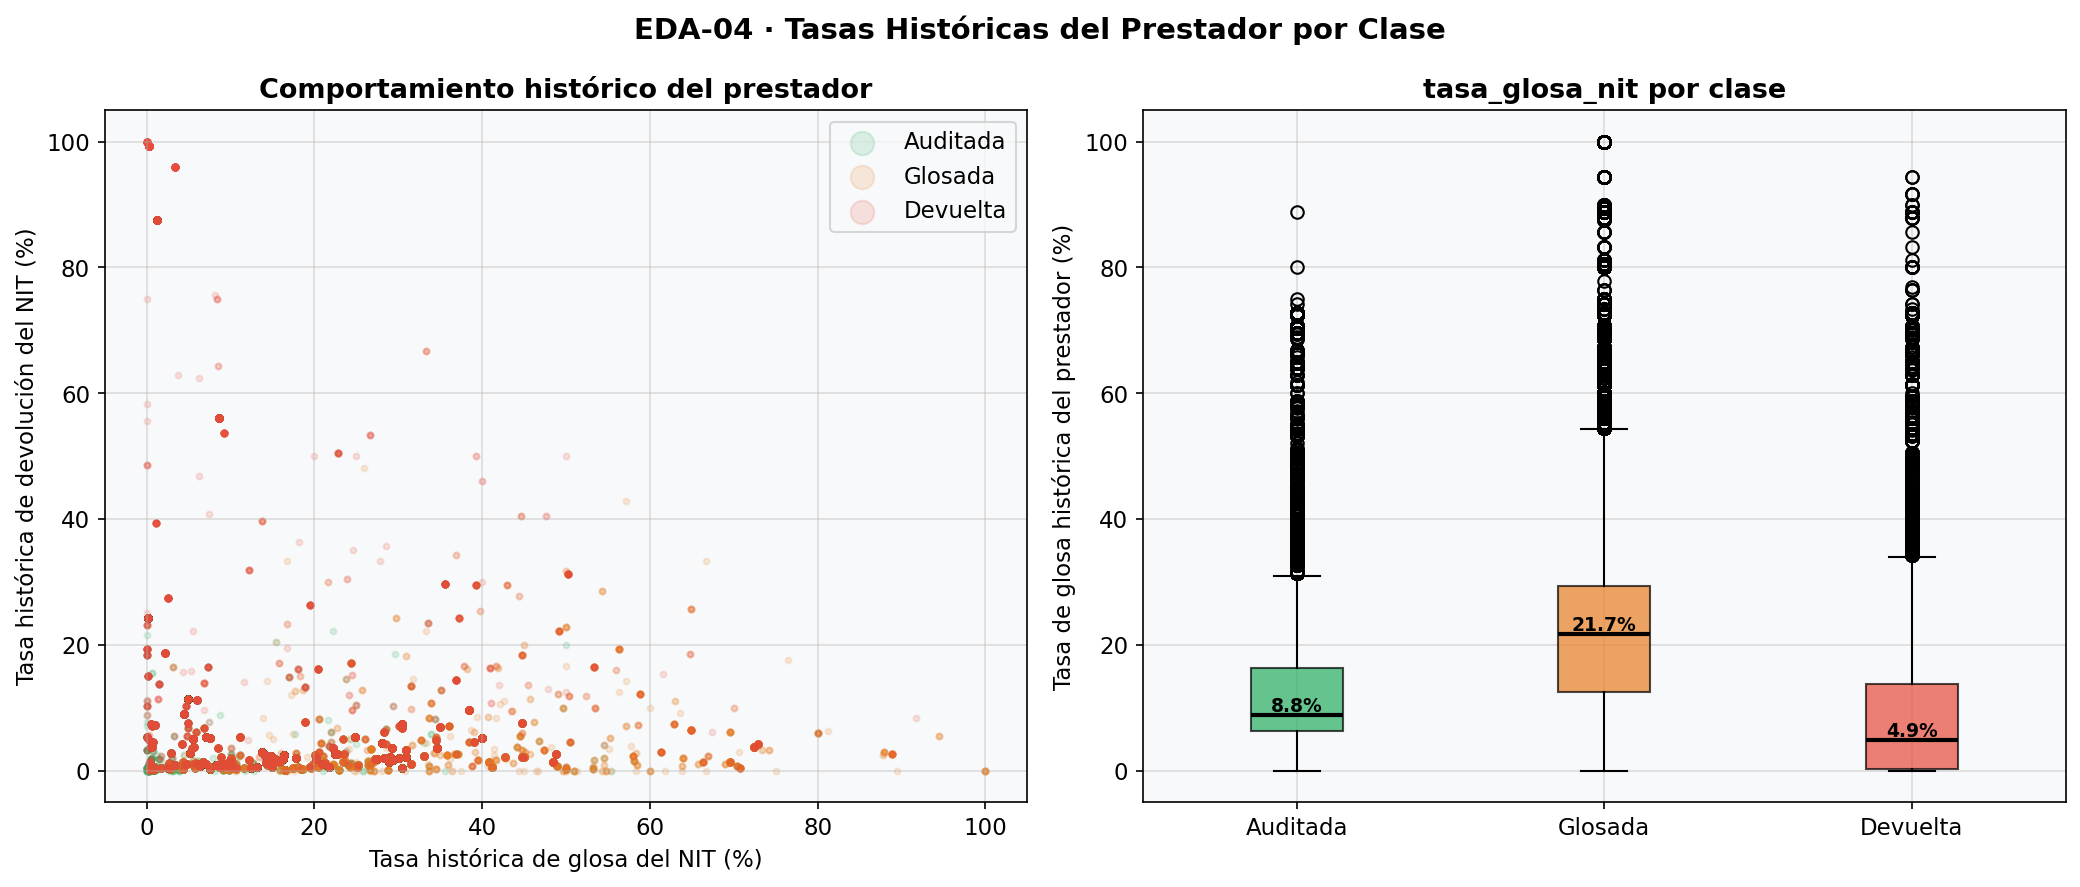


Mediana tasa_glosa_nit por clase:
  Clase 0 (Auditada): mediana=8.8%  media=12.1%
  Clase 1 (Glosada ): mediana=21.7%  media=22.1%
  Clase 2 (Devuelta): mediana=4.9%  media=8.9%


In [6]:
# Celda 6 — EDA-04: tasa_glosa_nit vs tasa_devolucion_nit (scatter por clase)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('EDA-04 · Tasas Históricas del Prestador por Clase', fontsize=14, fontweight='bold')

# Scatter: tasa_glosa_nit vs tasa_devolucion_nit
ax = axes[0]
sample = df.sample(min(50_000, len(df)), random_state=42)  # muestra para scatter legible
for cls in range(3):
    sub = sample[sample['target'] == cls]
    ax.scatter(sub['tasa_glosa_nit'], sub['tasa_devolucion_nit'],
               alpha=0.15, s=8, color=PALETTE[cls], label=LABELS[cls])
ax.set_xlabel('Tasa histórica de glosa del NIT (%)')
ax.set_ylabel('Tasa histórica de devolución del NIT (%)')
ax.set_title('Comportamiento histórico del prestador')
ax.legend(markerscale=4)

# Boxplot: tasa_glosa_nit por clase
ax2 = axes[1]
data_glosa = [df[df['target'] == cls]['tasa_glosa_nit'].values for cls in range(3)]
bp = ax2.boxplot(data_glosa, labels=[LABELS[i] for i in range(3)], patch_artist=True,
                 medianprops={'color': 'black', 'linewidth': 2})
for patch, color in zip(bp['boxes'], COLORS):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax2.set_title('tasa_glosa_nit por clase')
ax2.set_ylabel('Tasa de glosa histórica del prestador (%)')
for i, cls in enumerate(range(3)):
    med = np.median(data_glosa[i])
    ax2.text(i+1, med + 0.5, f'{med:.1f}%', ha='center', fontsize=9, fontweight='bold')

plt.tight_layout()
save_fig('eda_04_tasas_prestador.png')
plt.show()

print('\nMediana tasa_glosa_nit por clase:')
for cls in range(3):
    med = df[df['target'] == cls]['tasa_glosa_nit'].median()
    mean = df[df['target'] == cls]['tasa_glosa_nit'].mean()
    print(f'  Clase {cls} ({LABELS[cls]:8s}): mediana={med:.1f}%  media={mean:.1f}%')

  💾 Guardado: eda_05_correlaciones.png


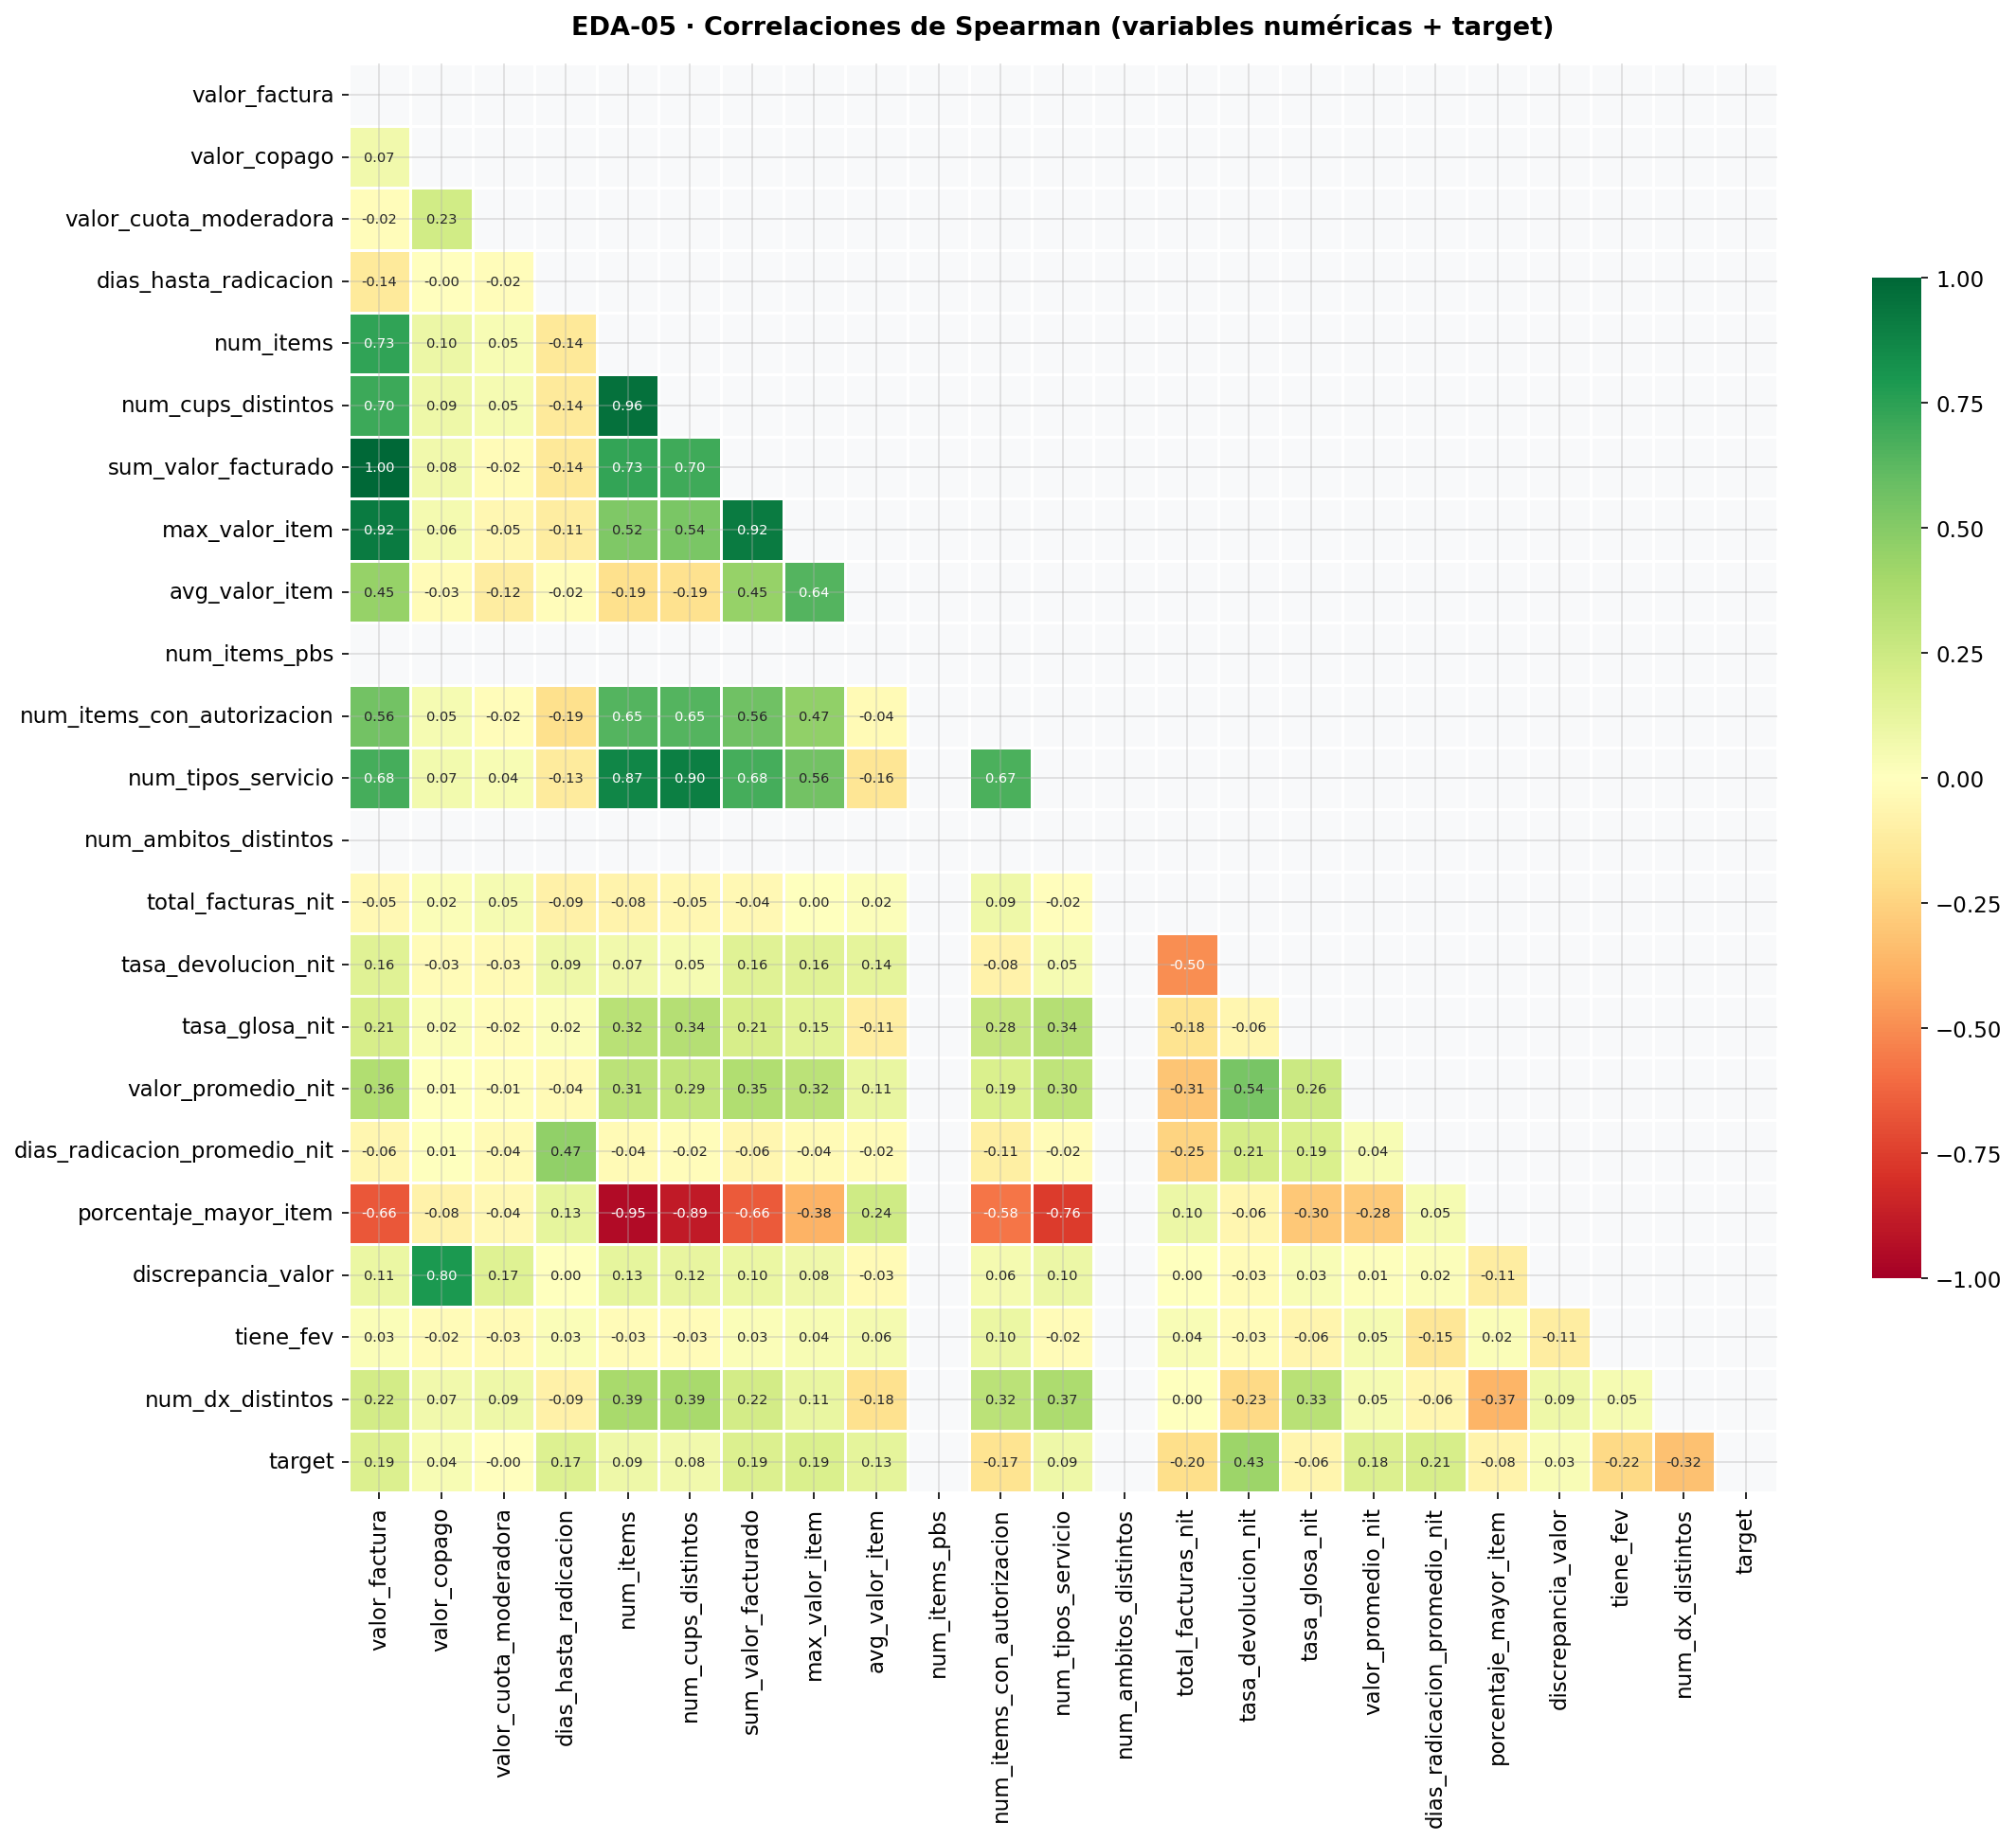


Top 10 variables más correlacionadas con target (Spearman):
  +0.428  tasa_devolucion_nit
  -0.323  num_dx_distintos
  -0.219  tiene_fev
  +0.208  dias_radicacion_promedio_nit
  -0.199  total_facturas_nit
  +0.190  max_valor_item
  +0.186  sum_valor_facturado
  +0.186  valor_factura
  +0.184  valor_promedio_nit
  -0.174  num_items_con_autorizacion


In [7]:
# Celda 7 — EDA-05: Heatmap de correlaciones numéricas

# Seleccionar columnas numéricas relevantes (excluir IDs, encoded y fechas)
COLS_EXCLUIR = ['factura_id', 'target', 'tipo_contrato_encoded', 'regimen_encoded',
                'mes_radicacion', 'trimestre_radicacion', 'anio_radicacion',
                'origen_factura', 'valor_factura_original']
num_cols = [c for c in df.select_dtypes(include='number').columns if c not in COLS_EXCLUIR]

corr_matrix = df[num_cols + ['target']].corr(method='spearman')

fig, ax = plt.subplots(figsize=(16, 13))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix, mask=mask, ax=ax,
    cmap='RdYlGn', center=0, vmin=-1, vmax=1,
    annot=True, fmt='.2f', annot_kws={'size': 7},
    linewidths=0.5, square=True, cbar_kws={'shrink': 0.7}
)
ax.set_title('EDA-05 · Correlaciones de Spearman (variables numéricas + target)', pad=15)
plt.tight_layout()
save_fig('eda_05_correlaciones.png')
plt.show()

# Top correlaciones con target
corr_target = corr_matrix['target'].drop('target').abs().sort_values(ascending=False)
print('\nTop 10 variables más correlacionadas con target (Spearman):')
for col, val in corr_target.head(10).items():
    direccion = '+' if corr_matrix.loc[col, 'target'] > 0 else '-'
    print(f'  {direccion}{val:.3f}  {col}')

  💾 Guardado: eda_06_top20_nit_glosa.png


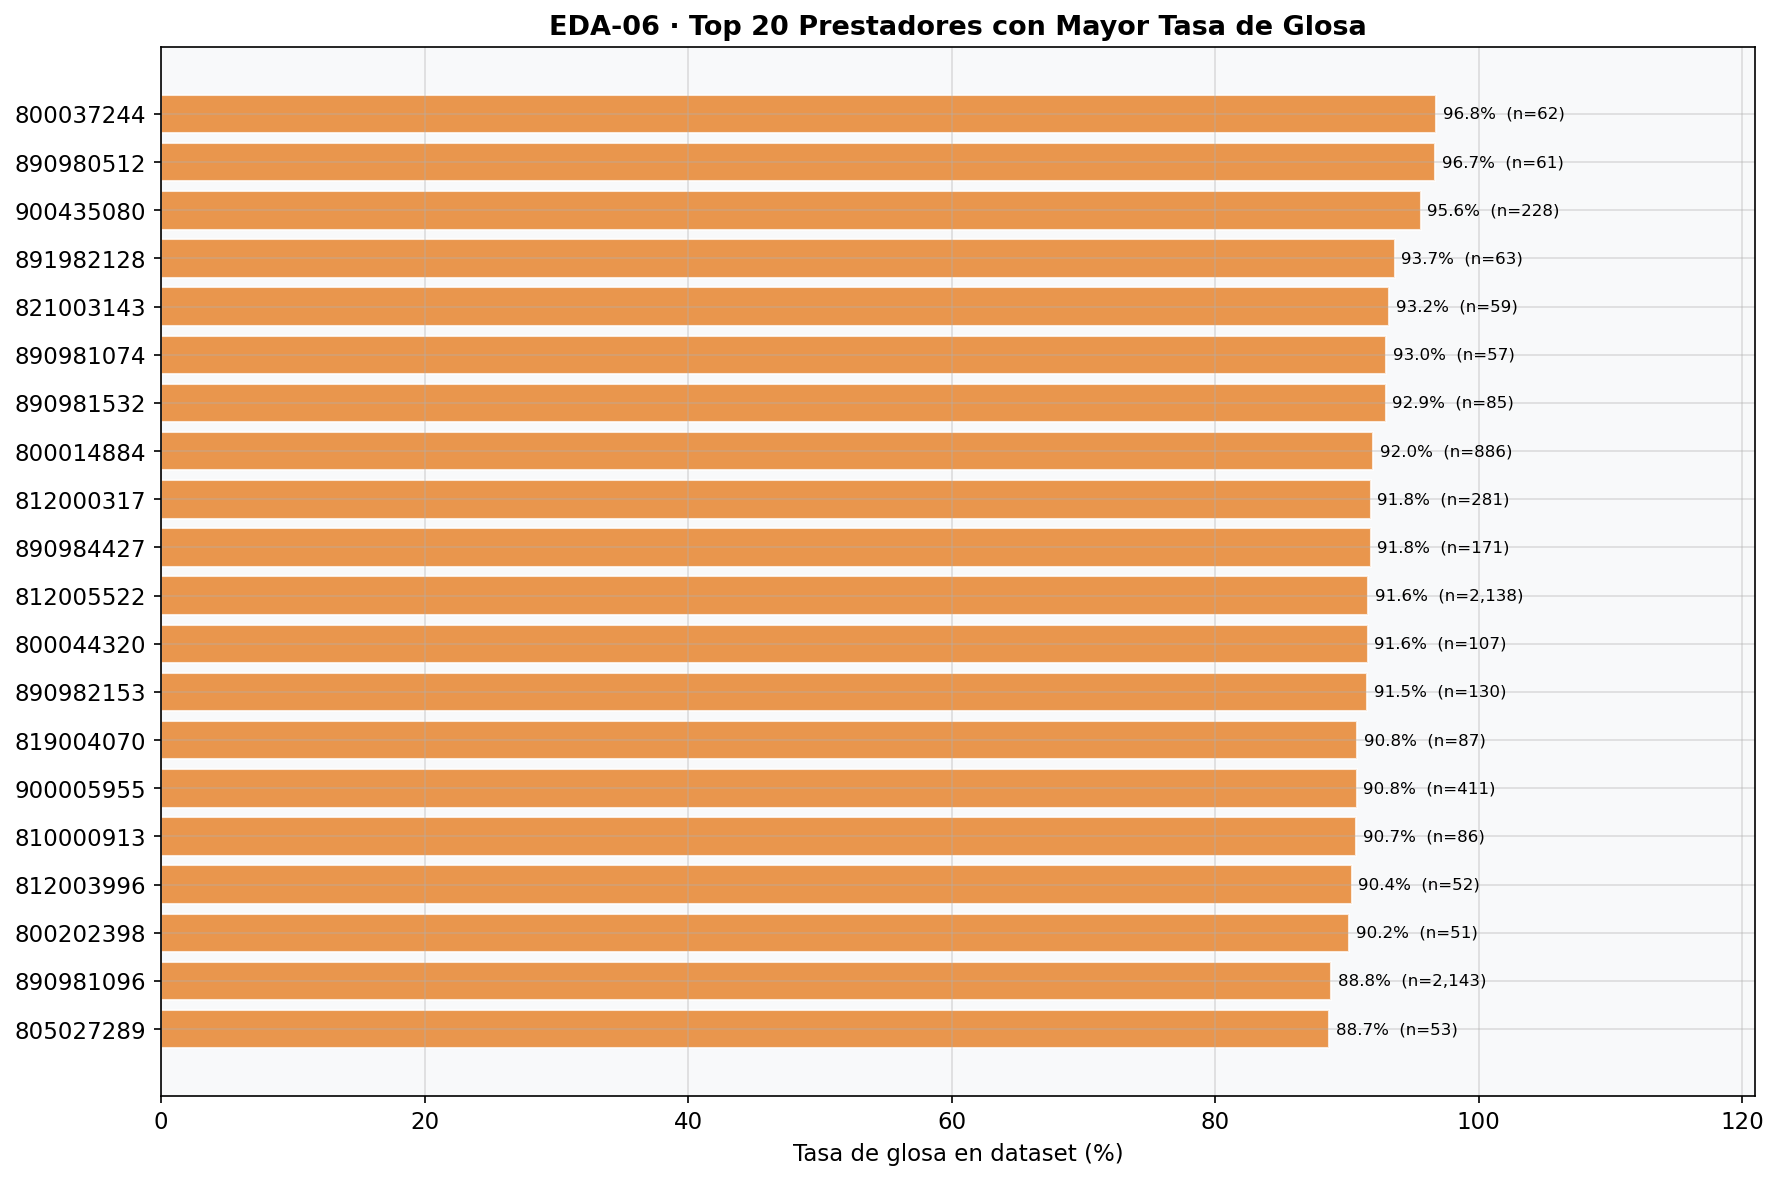


NITs analizados (≥50 facturas): 312
Tasa de glosa promedio por NIT: 51.7%
NIT con mayor tasa: 800037244  →  96.8%


In [8]:
# Celda 8 — EDA-06: Top-20 NITs prestadores con mayor tasa de glosa

# Agrupar por NIT: calcular tasa de glosa real en el dataset
nit_stats = (
    df.groupby('nit_prestador')
    .agg(
        total=('target', 'count'),
        glosadas=('target', lambda x: (x == 1).sum()),
        devueltas=('target', lambda x: (x == 2).sum()),
        tasa_glosa_historica=('tasa_glosa_nit', 'mean'),
        valor_promedio=('valor_factura', 'median'),
    )
    .reset_index()
)
nit_stats['tasa_glosa_real'] = nit_stats['glosadas'] / nit_stats['total'] * 100
nit_stats = nit_stats[nit_stats['total'] >= 50]  # solo NITs con ≥ 50 facturas

top20 = nit_stats.nlargest(20, 'tasa_glosa_real')

fig, ax = plt.subplots(figsize=(12, 8))
bars = ax.barh(
    top20['nit_prestador'].astype(str),
    top20['tasa_glosa_real'],
    color=PALETTE[1], alpha=0.8, edgecolor='white'
)
for bar, (_, row) in zip(bars, top20.iterrows()):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
            f'{row["tasa_glosa_real"]:.1f}%  (n={int(row["total"]):,})',
            va='center', fontsize=8)
ax.set_xlabel('Tasa de glosa en dataset (%)')
ax.set_title('EDA-06 · Top 20 Prestadores con Mayor Tasa de Glosa')
ax.set_xlim(0, top20['tasa_glosa_real'].max() * 1.25)
ax.invert_yaxis()
plt.tight_layout()
save_fig('eda_06_top20_nit_glosa.png')
plt.show()

print(f'\nNITs analizados (≥50 facturas): {len(nit_stats):,}')
print(f'Tasa de glosa promedio por NIT: {nit_stats["tasa_glosa_real"].mean():.1f}%')
print(f'NIT con mayor tasa: {top20.iloc[0]["nit_prestador"]}  →  {top20.iloc[0]["tasa_glosa_real"]:.1f}%')

  💾 Guardado: eda_07_serie_temporal.png


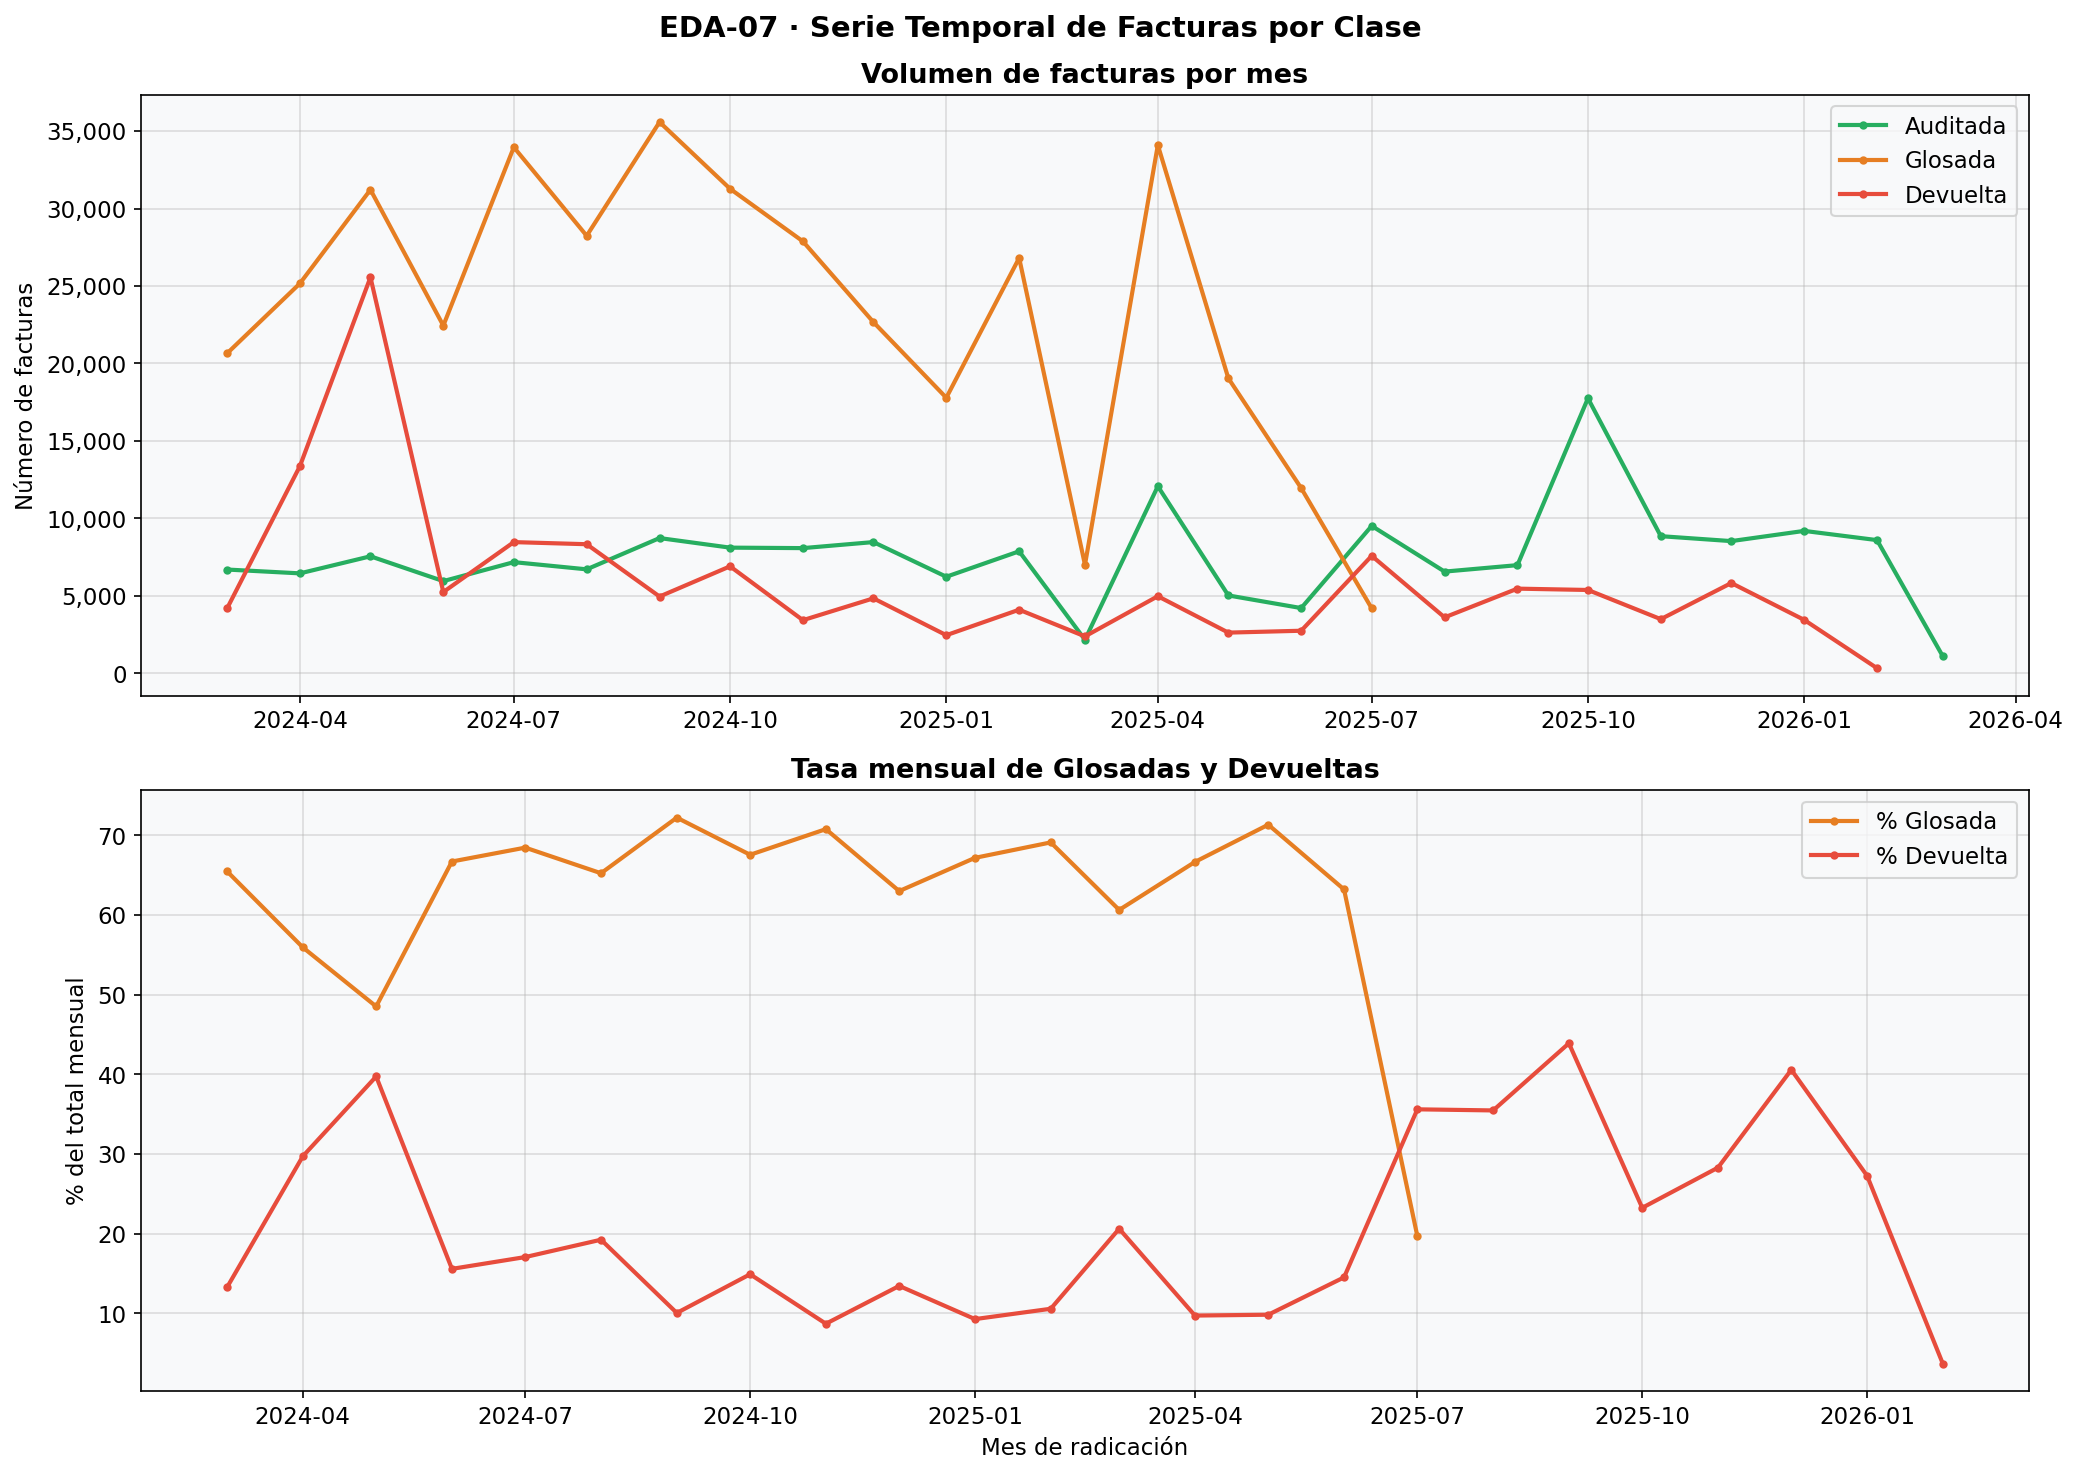

In [9]:
# Celda 9 — EDA-07: Serie temporal de facturas por mes y clase

df['periodo'] = pd.to_datetime(df['fecha_radicacion']).dt.to_period('M')

serie = (
    df.groupby(['periodo', 'target'])
    .size()
    .reset_index(name='count')
)
serie['periodo_dt'] = serie['periodo'].dt.to_timestamp()

fig, axes = plt.subplots(2, 1, figsize=(14, 10))
fig.suptitle('EDA-07 · Serie Temporal de Facturas por Clase', fontsize=14, fontweight='bold')

# Panel A: Volumen absoluto
ax = axes[0]
for cls in range(3):
    sub = serie[serie['target'] == cls].sort_values('periodo_dt')
    ax.plot(sub['periodo_dt'], sub['count'], color=PALETTE[cls],
            label=LABELS[cls], linewidth=2, marker='o', markersize=3)
ax.set_title('Volumen de facturas por mes')
ax.set_ylabel('Número de facturas')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax.legend()

# Panel B: Proporción de glosas/devoluciones por mes
ax2 = axes[1]
total_mes = serie.groupby('periodo_dt')['count'].sum().reset_index(name='total')
for cls in [1, 2]:
    sub = serie[serie['target'] == cls].sort_values('periodo_dt')
    sub = sub.merge(total_mes, on='periodo_dt')
    sub['pct'] = sub['count'] / sub['total'] * 100
    ax2.plot(sub['periodo_dt'], sub['pct'], color=PALETTE[cls],
             label=f'% {LABELS[cls]}', linewidth=2, marker='o', markersize=3)
ax2.set_title('Tasa mensual de Glosadas y Devueltas')
ax2.set_ylabel('% del total mensual')
ax2.set_xlabel('Mes de radicación')
ax2.legend()

plt.tight_layout()
save_fig('eda_07_serie_temporal.png')
plt.show()

EDA-08 · COMPLETITUD Y CALIDAD DE DATOS

✅ Sin valores nulos en ninguna columna.

Facturas sin items en cm_detalles (num_items=0): 39 (0.01%)
  Distribución por clase:
    Clase 0 (Auditada): 0
    Clase 1 (Glosada): 0
    Clase 2 (Devuelta): 39

Rango de variables clave (post-corrección):
  valor_factura                 : min=0.0  p01=6800.0  p99=59871712.2  max=348497203.7  zeros=2
  dias_hasta_radicacion         : min=0.0  p01=1.0  p99=365.0  max=365.0  zeros=1,946
  num_items                     : min=0.0  p01=1.0  p99=673.0  max=490261.0  zeros=39
  num_dx_distintos              : min=0.0  p01=0.0  p99=10.0  max=2531.0  zeros=71,783
  tasa_glosa_nit                : min=0.0  p01=0.1  p99=64.9  max=100.0  zeros=1,796
  porcentaje_mayor_item         : min=0.0  p01=0.0  p99=1.0  max=1.0  zeros=516
  💾 Guardado: eda_08_completitud.png


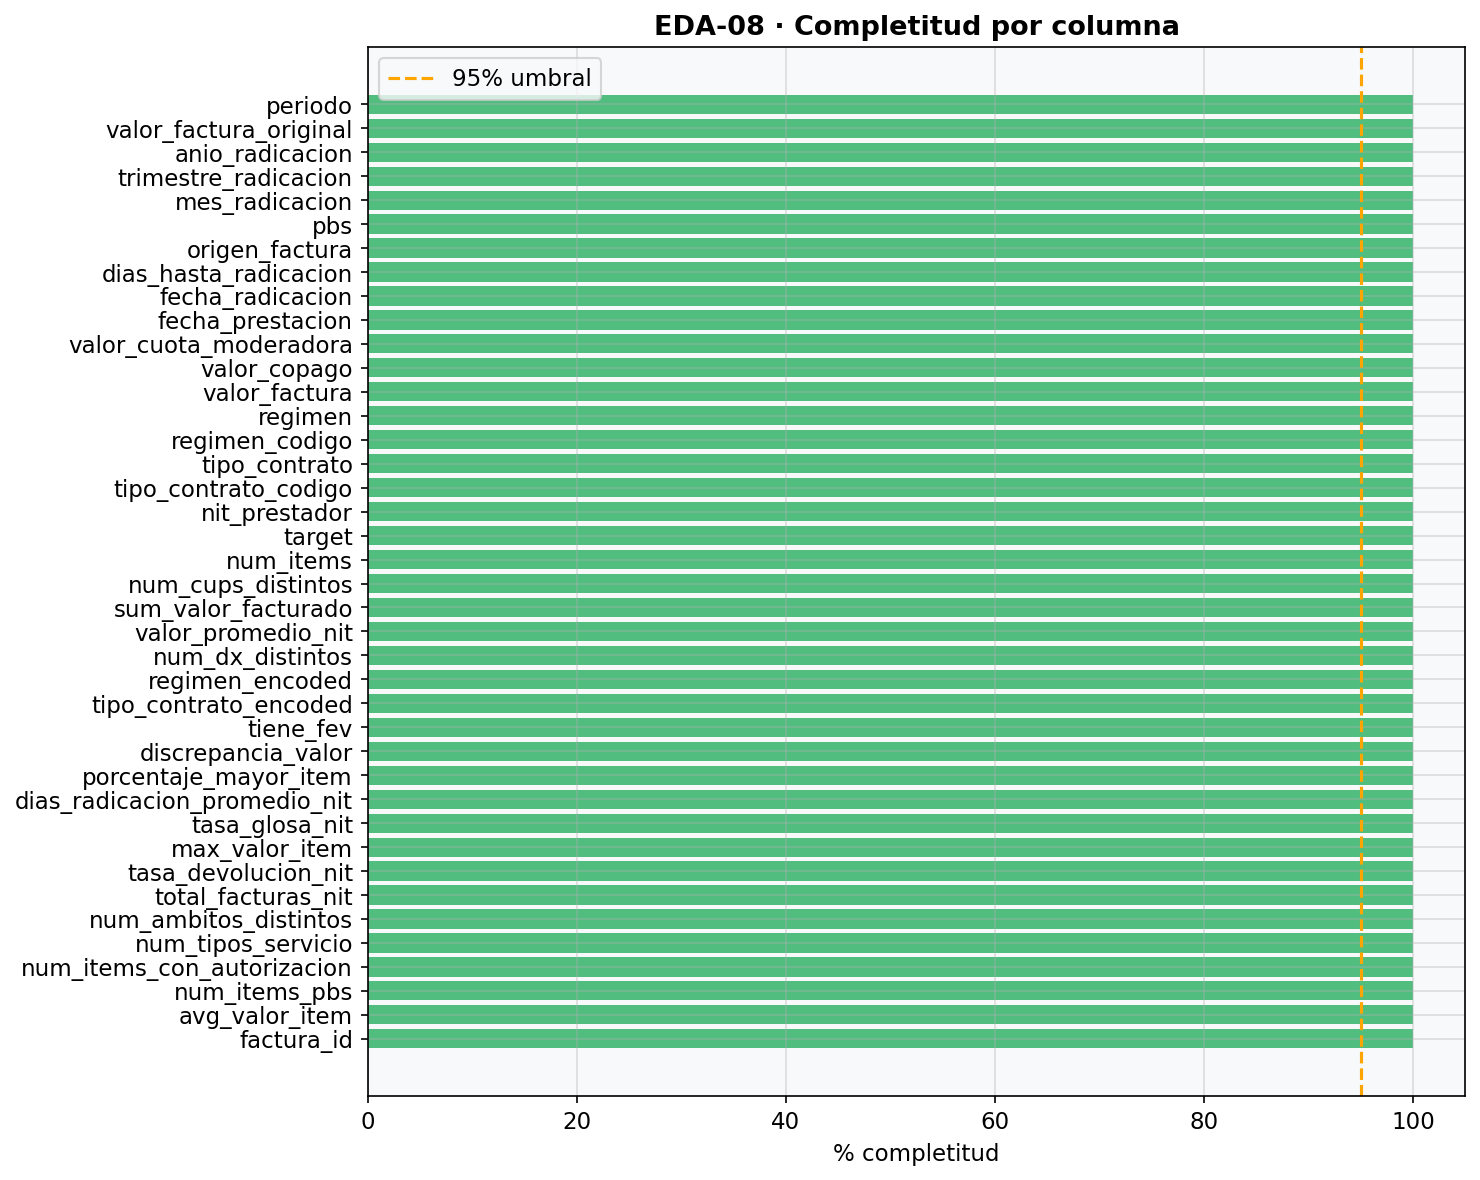

In [11]:
# Celda 10 — EDA-08: Análisis de completitud y outliers

print('=' * 60)
print('EDA-08 · COMPLETITUD Y CALIDAD DE DATOS')
print('=' * 60)

# Completitud por columna
nulls = df.isnull().sum()
nulls_pct = (nulls / len(df) * 100).round(1)
completitud = pd.DataFrame({'nulos': nulls, 'pct_nulos': nulls_pct})
completitud_problemas = completitud[completitud['nulos'] > 0].sort_values('pct_nulos', ascending=False)

if len(completitud_problemas) > 0:
    print(f'\nColumnas con nulos ({len(completitud_problemas)}):')
    print(completitud_problemas.to_string())
else:
    print('\n✅ Sin valores nulos en ninguna columna.')

# Facturas sin detalles (num_items = 0)
sin_detalles = (df['num_items'] == 0).sum()
print(f'\nFacturas sin items en cm_detalles (num_items=0): {sin_detalles:,} ({sin_detalles/len(df)*100:.2f}%)')
if sin_detalles > 0:
    print('  Distribución por clase:')
    for cls in range(3):
        cnt = ((df['target'] == cls) & (df['num_items'] == 0)).sum()
        print(f'    Clase {cls} ({LABELS[cls]}): {cnt:,}')

# Outliers en variables clave (post-limpieza)
print('\nRango de variables clave (post-corrección):')
check_cols = ['valor_factura', 'dias_hasta_radicacion', 'num_items',
              'num_dx_distintos', 'tasa_glosa_nit', 'porcentaje_mayor_item']
for col in check_cols:
    s = df[col]
    p01, p99 = s.quantile(0.01), s.quantile(0.99)
    print(f'  {col:<30}: min={s.min():.1f}  p01={p01:.1f}  p99={p99:.1f}  max={s.max():.1f}  zeros={( s==0).sum():,}')

# Gráfico de completitud
fig, ax = plt.subplots(figsize=(10, 8))
completitud_all = (1 - df.isnull().mean()) * 100
completitud_all = completitud_all.sort_values()
col_colors = ['#e74c3c' if v < 95 else '#27ae60' for v in completitud_all]
ax.barh(completitud_all.index, completitud_all.values, color=col_colors, alpha=0.8)
ax.axvline(95, color='orange', linestyle='--', label='95% umbral')
ax.set_xlabel('% completitud')
ax.set_title('EDA-08 · Completitud por columna')
ax.set_xlim(0, 105)
ax.legend()
plt.tight_layout()
save_fig('eda_08_completitud.png')
plt.show()

  💾 Guardado: eda_09_features_discriminadoras.png


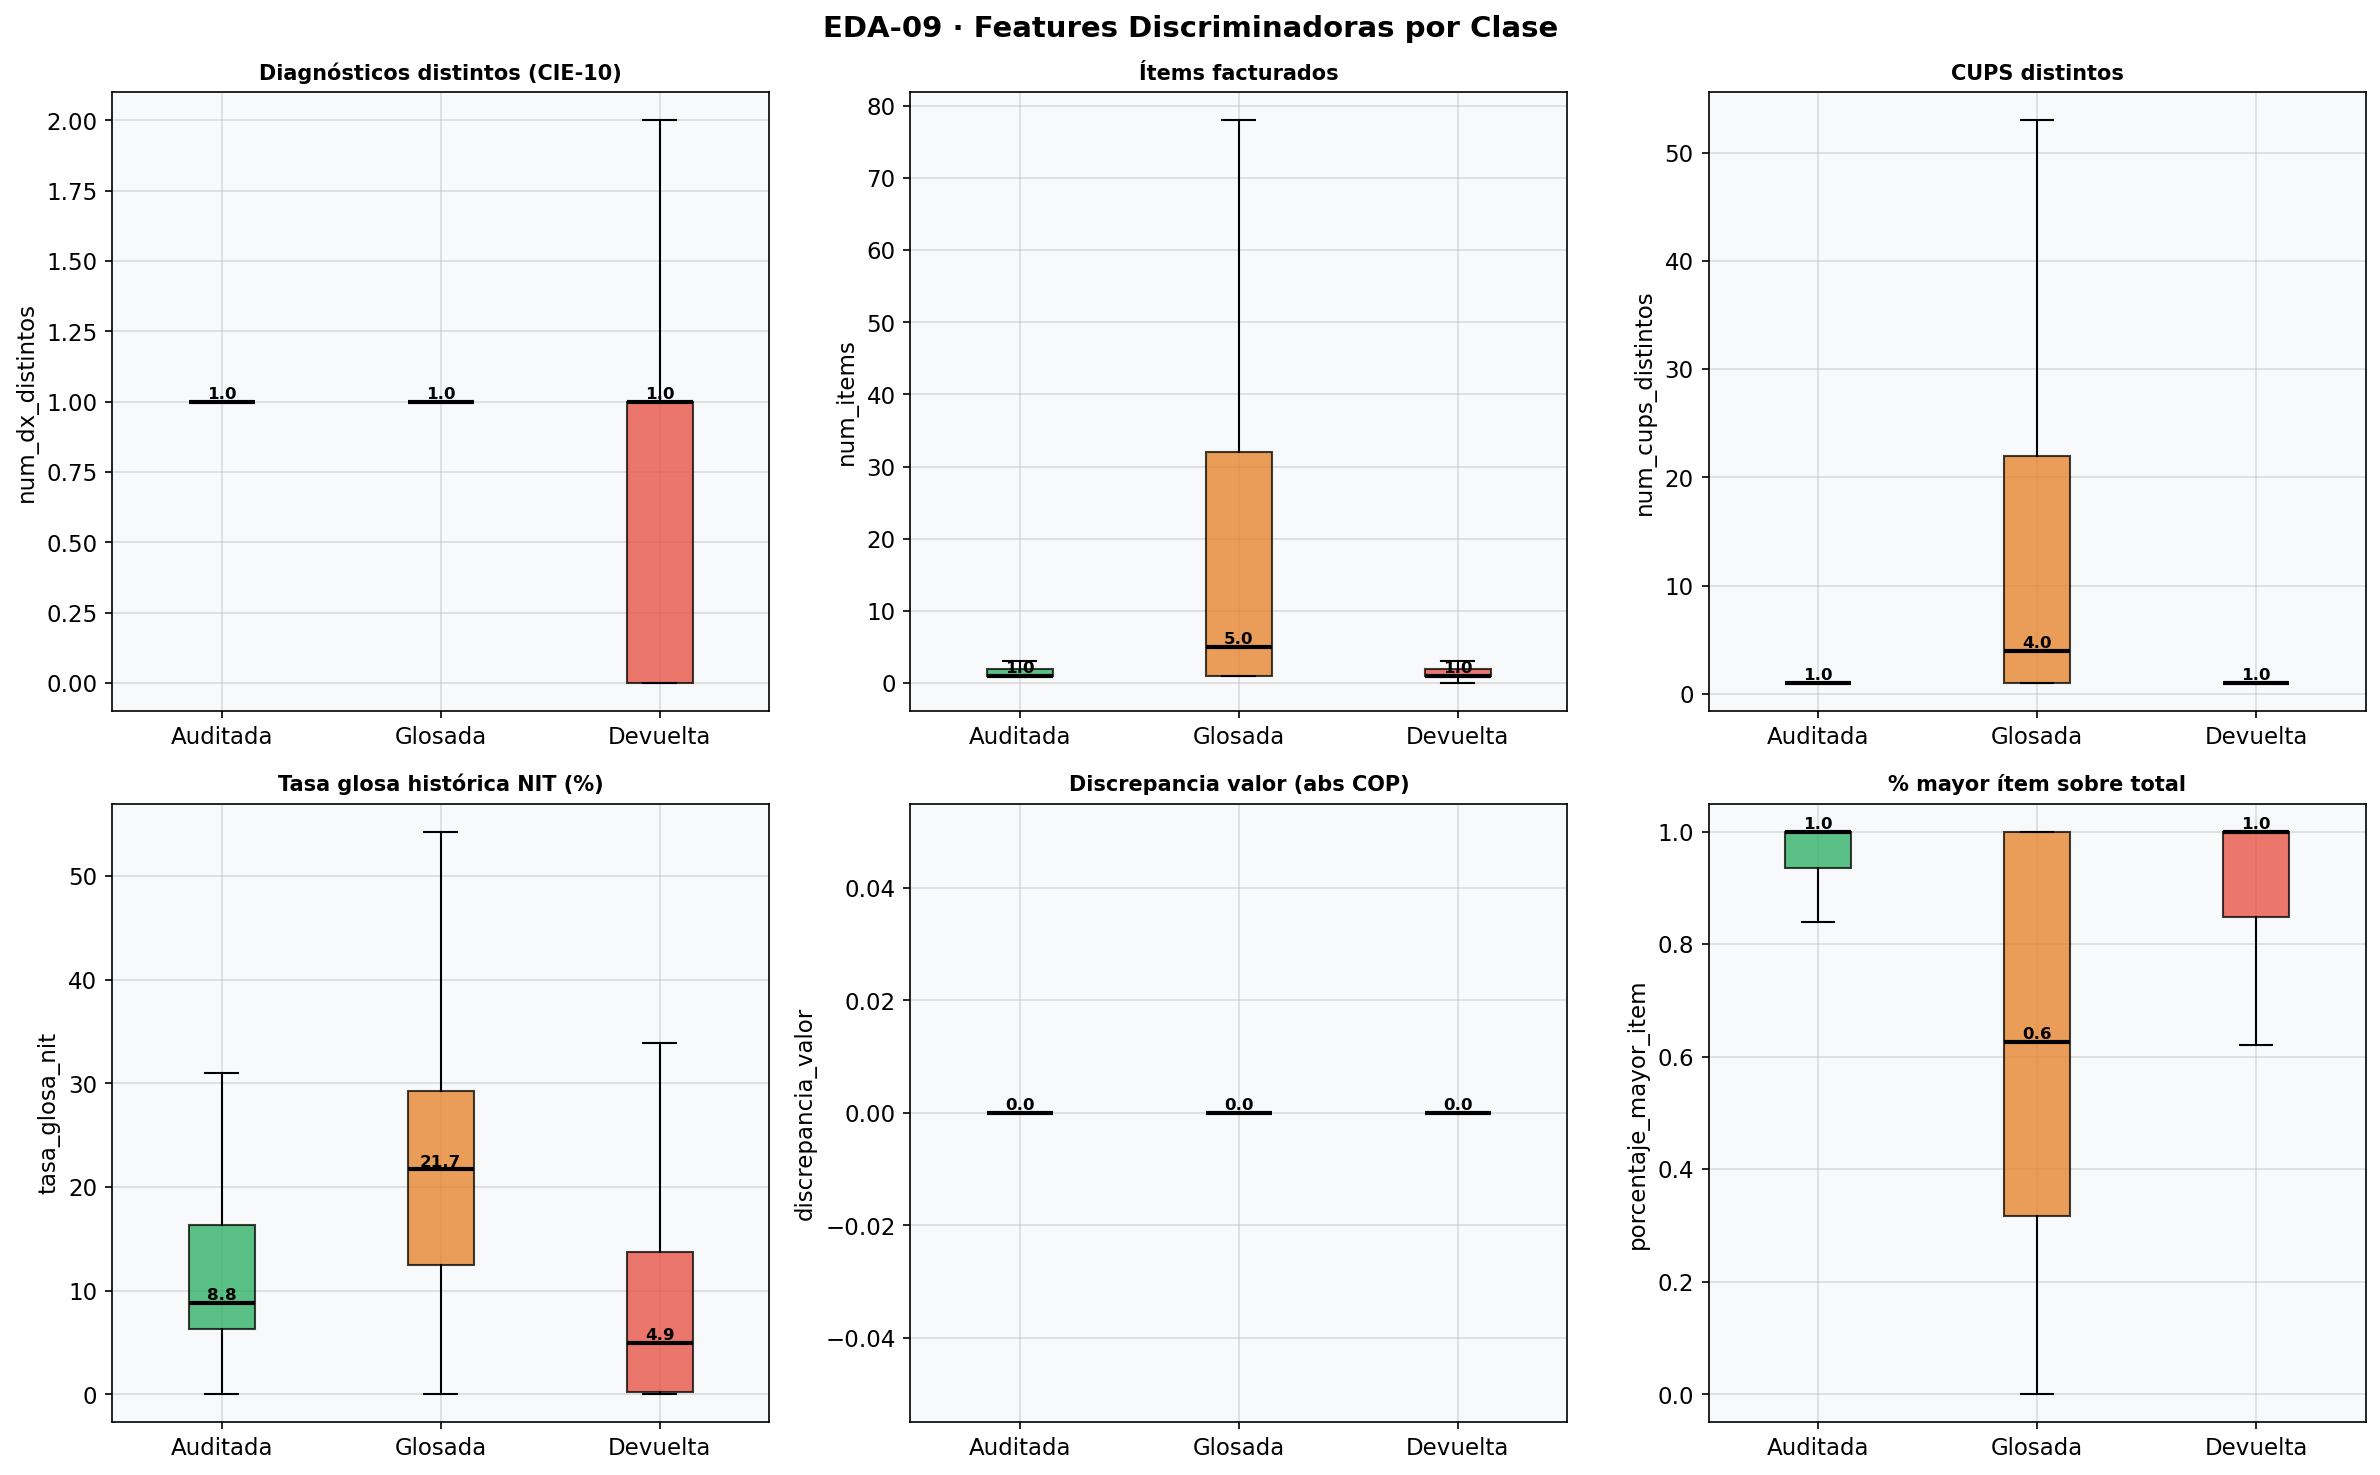


Medianas por clase de features clave:
Feature                             Auditada       Glosada      Devuelta
------------------------------------------------------------------------
Diagnósticos distintos (CIE-10)          1.00          1.00          1.00
Ítems facturados                        1.00          5.00          1.00
CUPS distintos                          1.00          4.00          1.00
Tasa glosa histórica NIT (%)            8.83         21.69          4.93
Discrepancia valor (abs COP)            0.00          0.00          0.00
% mayor ítem sobre total                1.00          0.63          1.00


In [12]:
# Celda 11 — EDA-09: Features discriminadoras clave
# num_dx_distintos, num_items, valor_factura, tasa_glosa_nit

features_key = [
    ('num_dx_distintos',    'Diagnósticos distintos (CIE-10)'),
    ('num_items',           'Ítems facturados'),
    ('num_cups_distintos',  'CUPS distintos'),
    ('tasa_glosa_nit',      'Tasa glosa histórica NIT (%)'),
    ('discrepancia_valor',  'Discrepancia valor (abs COP)'),
    ('porcentaje_mayor_item','% mayor ítem sobre total'),
]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('EDA-09 · Features Discriminadoras por Clase', fontsize=14, fontweight='bold')

for ax, (col, titulo) in zip(axes.flatten(), features_key):
    data = [df[df['target'] == cls][col].values for cls in range(3)]
    bp = ax.boxplot(data, labels=[LABELS[i] for i in range(3)], patch_artist=True,
                    medianprops={'color': 'black', 'linewidth': 2},
                    showfliers=False)  # sin outliers individuales para claridad
    for patch, color in zip(bp['boxes'], COLORS):
        patch.set_facecolor(color)
        patch.set_alpha(0.75)
    ax.set_title(titulo, fontsize=10)
    ax.set_ylabel(col)
    # Mediana anotada
    for i, cls in enumerate(range(3)):
        med = np.median(data[i])
        ax.text(i+1, med, f'{med:.1f}', ha='center', va='bottom', fontsize=8, fontweight='bold')

plt.tight_layout()
save_fig('eda_09_features_discriminadoras.png')
plt.show()

print('\nMedianas por clase de features clave:')
print(f'{"Feature":<30}  {"Auditada":>12}  {"Glosada":>12}  {"Devuelta":>12}')
print('-' * 72)
for col, titulo in features_key:
    vals = [df[df['target'] == cls][col].median() for cls in range(3)]
    print(f'{titulo:<30}  {vals[0]:>12.2f}  {vals[1]:>12.2f}  {vals[2]:>12.2f}')

  💾 Guardado: eda_10_variables_categoricas.png


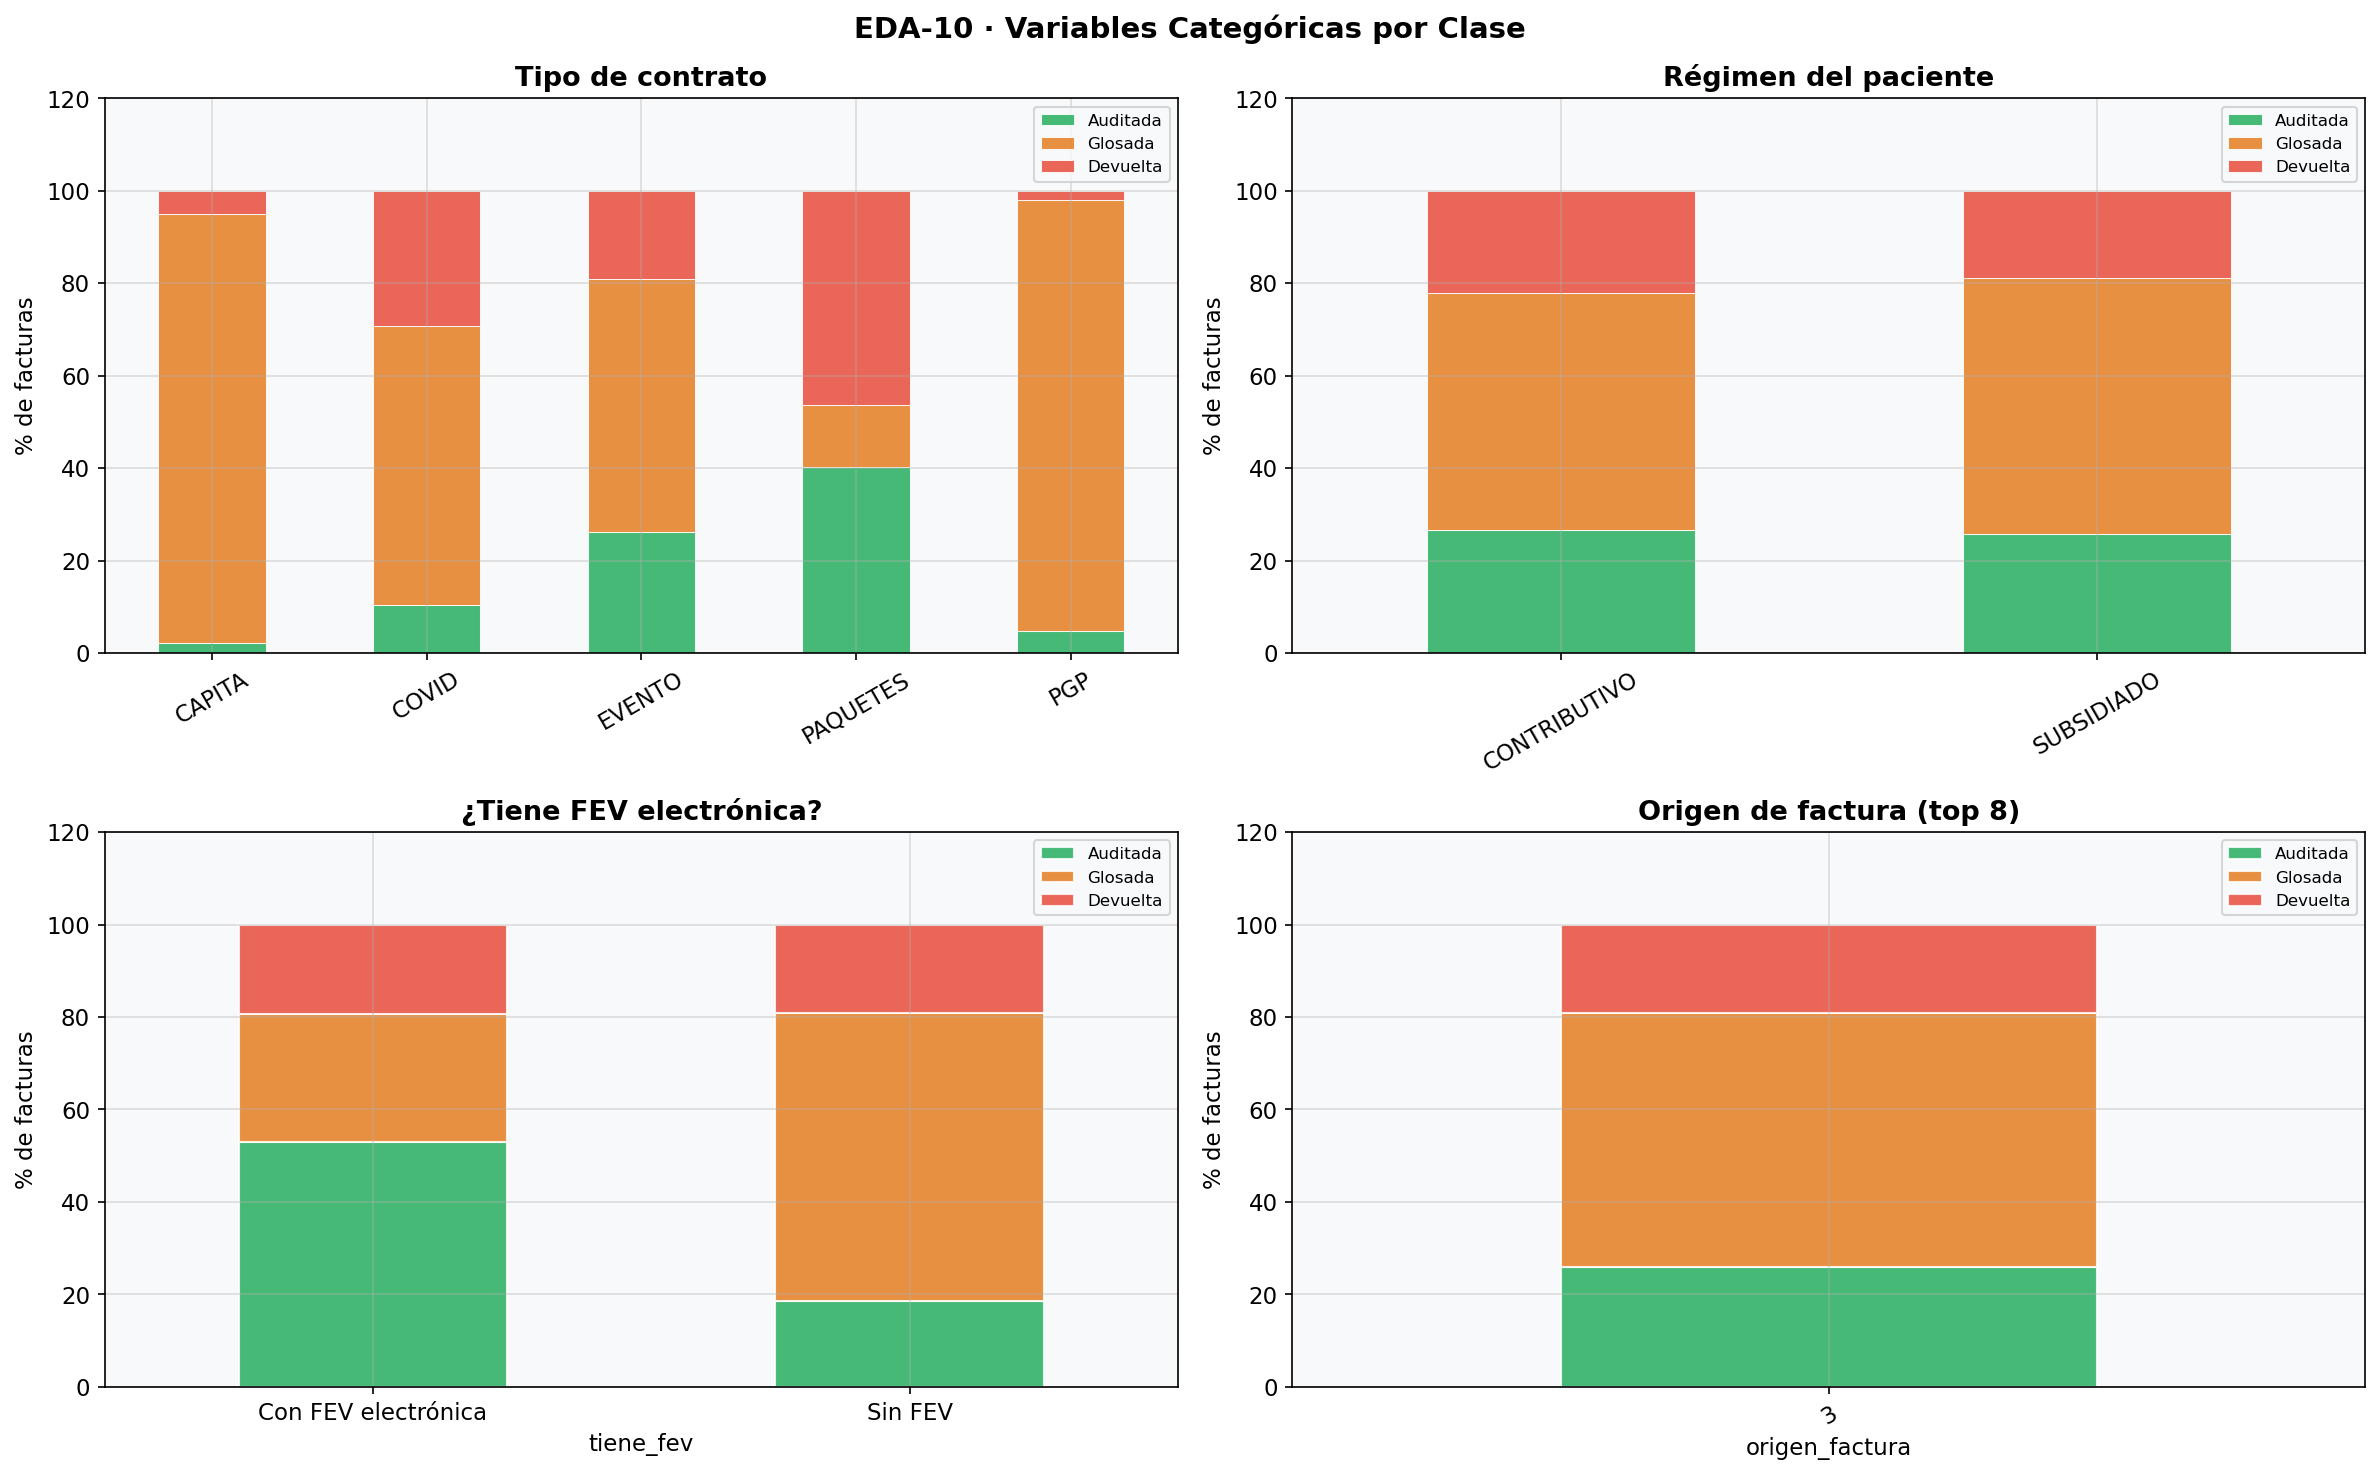

In [13]:
# Celda 12 — EDA-10: Variables categóricas

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('EDA-10 · Variables Categóricas por Clase', fontsize=14, fontweight='bold')

def plot_cat_stacked(ax, col, titulo):
    """Barras apiladas 100% por categoría."""
    ct = pd.crosstab(df[col], df['target'], normalize='index') * 100
    ct.columns = [LABELS[c] for c in ct.columns]
    ct.plot(kind='bar', stacked=True, ax=ax, color=COLORS, alpha=0.85,
            edgecolor='white', linewidth=0.5)
    ax.set_title(titulo)
    ax.set_ylabel('% de facturas')
    ax.set_xlabel('')
    ax.legend(loc='upper right', fontsize=8)
    ax.set_ylim(0, 120)
    for tick in ax.get_xticklabels():
        tick.set_rotation(30)

plot_cat_stacked(axes[0, 0], 'tipo_contrato',  'Tipo de contrato')
plot_cat_stacked(axes[0, 1], 'regimen',         'Régimen del paciente')

# tiene_fev
ax = axes[1, 0]
ct_fev = pd.crosstab(df['tiene_fev'].map({0: 'Sin FEV', 1: 'Con FEV electrónica'}),
                     df['target'], normalize='index') * 100
ct_fev.columns = [LABELS[c] for c in ct_fev.columns]
ct_fev.plot(kind='bar', stacked=True, ax=ax, color=COLORS, alpha=0.85, edgecolor='white')
ax.set_title('¿Tiene FEV electrónica?')
ax.set_ylabel('% de facturas')
ax.set_ylim(0, 120)
ax.legend(fontsize=8)
for tick in ax.get_xticklabels():
    tick.set_rotation(0)

# origen_factura
ax2 = axes[1, 1]
ct_orig = pd.crosstab(df['origen_factura'], df['target'], normalize='index') * 100
ct_orig.columns = [LABELS[c] for c in ct_orig.columns]
top_origenes = df['origen_factura'].value_counts().head(8).index
ct_orig.loc[top_origenes].plot(kind='bar', stacked=True, ax=ax2, color=COLORS, alpha=0.85, edgecolor='white')
ax2.set_title('Origen de factura (top 8)')
ax2.set_ylabel('% de facturas')
ax2.set_ylim(0, 120)
ax2.legend(fontsize=8)
for tick in ax2.get_xticklabels():
    tick.set_rotation(30)

plt.tight_layout()
save_fig('eda_10_variables_categoricas.png')
plt.show()

Consultando predicciones sistema IA Savia...
→ 50,000 facturas con predicción del sistema Savia (10.5s)

Tipos: pred_savia=object  estado_real_savia=int64
Valores únicos pred_savia:       ['0']
Valores únicos estado_real_savia: [0, 2, 3, 4, 5]

Valores int pred_savia:  [0]
Valores int real_savia:  [0, 2, 3, 4, 5]
Facturas en benchmark (con target): 50,000

=== BASELINE: Sistema IA Savia vs TARGET real del dataset ===
N facturas evaluadas: 50,000
Accuracy:   0.259
F1-macro:   0.137

Reporte por clase:
              precision    recall  f1-score   support

    Auditada       0.26      1.00      0.41     12952
     Glosada       0.00      0.00      0.00     27550
    Devuelta       0.00      0.00      0.00      9498

    accuracy                           0.26     50000
   macro avg       0.09      0.33      0.14     50000
weighted avg       0.07      0.26      0.11     50000

  💾 Guardado: eda_11_baseline_savia.png


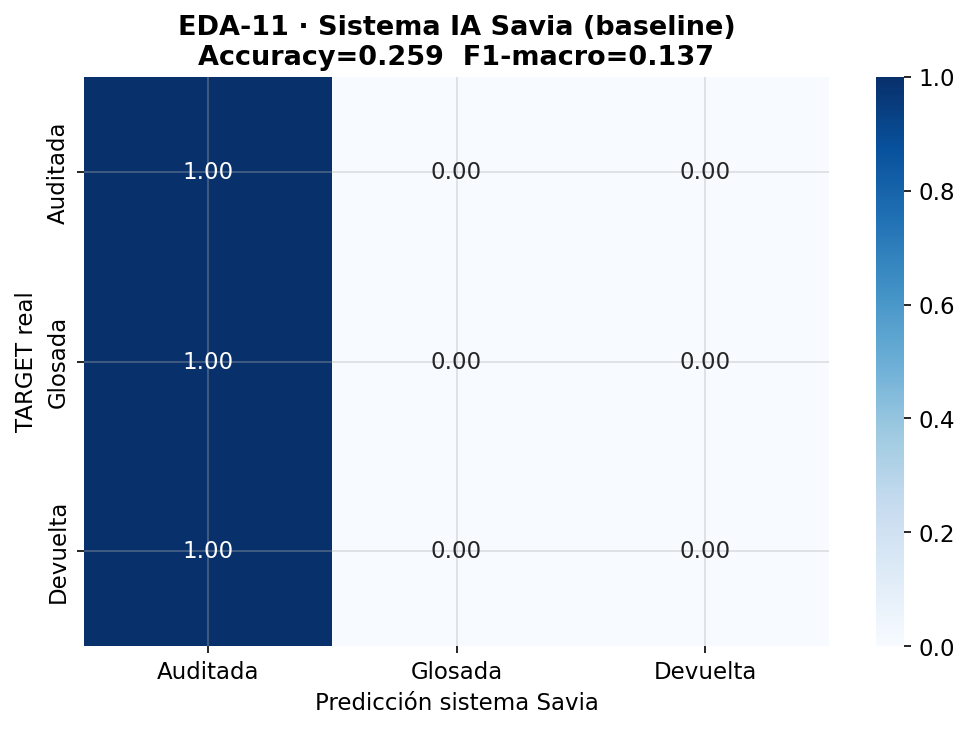


📌 HALLAZGO BASELINE: Acc=0.259  F1-macro=0.137
   Nuestro modelo debe superar estas métricas para justificar el proyecto.


In [16]:
# Celda 13 — EDA-11: Baseline sistema IA Savia (ejecucion_glosa_aut_ia)
# NOTA: estas columnas NO están en el dataset de entrenamiento (excluidas por data leakage).
# Se consultan directamente desde la BD solo para benchmarking.

EJECUTAR_BENCHMARK = True  # Cambiar a False si no hay conexión a BD

if EJECUTAR_BENCHMARK:
    try:
        from sqlalchemy import create_engine
        from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
        import time

        user, password, host, db_name, port = "jcardonr", "6nxx2yVWaKXyiF1cZbfS*", "10.250.5.36", "system_savia", "3306"
        engine = create_engine(
            f"mysql+pymysql://{user}:{password}@{host}:{port}/{db_name}",
            connect_args={"connect_timeout": 30}, pool_recycle=3600,
        )

        sample_ids = df.sample(min(50_000, len(df)), random_state=42)['factura_id'].tolist()
        ids_str = ','.join(str(x) for x in sample_ids)

        q = f"""
        SELECT
            f.id                        AS factura_id,
            f.ejecucion_glosa_aut_ia    AS pred_savia,
            f.estado_glosa_aut          AS estado_real_savia
        FROM cm_facturas f
        WHERE f.id IN ({ids_str})
          AND f.ejecucion_glosa_aut_ia IS NOT NULL
          AND f.estado_glosa_aut IS NOT NULL
        """

        print('Consultando predicciones sistema IA Savia...')
        t0 = time.time()
        df_savia = pd.read_sql(q, con=engine)
        print(f'→ {len(df_savia):,} facturas con predicción del sistema Savia ({time.time()-t0:.1f}s)')

        # ── Diagnóstico de tipos y valores únicos ─────────────────
        print(f'\nTipos: pred_savia={df_savia["pred_savia"].dtype}  estado_real_savia={df_savia["estado_real_savia"].dtype}')
        print(f'Valores únicos pred_savia:       {sorted(df_savia["pred_savia"].dropna().unique().tolist())}')
        print(f'Valores únicos estado_real_savia: {sorted(df_savia["estado_real_savia"].dropna().unique().tolist())}')

        if len(df_savia) > 0:
            # ── Convertir a int de forma segura ───────────────────
            df_savia['pred_savia_int'] = pd.to_numeric(df_savia['pred_savia'], errors='coerce')
            df_savia['real_savia_int'] = pd.to_numeric(df_savia['estado_real_savia'], errors='coerce')

            # Descartar filas con valores no convertibles
            df_savia = df_savia.dropna(subset=['pred_savia_int', 'real_savia_int'])
            df_savia['pred_savia_int'] = df_savia['pred_savia_int'].astype(int)
            df_savia['real_savia_int'] = df_savia['real_savia_int'].astype(int)

            # Verificar que los valores están en {0, 1, 2}
            vals_pred = set(df_savia['pred_savia_int'].unique())
            vals_real = set(df_savia['real_savia_int'].unique())
            print(f'\nValores int pred_savia:  {sorted(vals_pred)}')
            print(f'Valores int real_savia:  {sorted(vals_real)}')

            # Merge con nuestro target (TARGET real del dataset)
            df_bench = df_savia.merge(df[['factura_id', 'target']], on='factura_id', how='inner')
            print(f'Facturas en benchmark (con target): {len(df_bench):,}')

            # ── Métricas: pred_savia vs TARGET del dataset ────────
            clases_presentes = sorted(df_bench['pred_savia_int'].unique().tolist() +
                                      df_bench['target'].unique().tolist())
            clases_presentes = sorted(set(clases_presentes) & {0, 1, 2})
            target_names_presentes = [LABELS[c] for c in clases_presentes]

            y_true = df_bench['target'].values
            y_pred = df_bench['pred_savia_int'].values

            acc  = accuracy_score(y_true, y_pred)
            f1m  = f1_score(y_true, y_pred, average='macro', labels=clases_presentes, zero_division=0)

            print('\n=== BASELINE: Sistema IA Savia vs TARGET real del dataset ===')
            print(f'N facturas evaluadas: {len(df_bench):,}')
            print(f'Accuracy:   {acc:.3f}')
            print(f'F1-macro:   {f1m:.3f}')
            print('\nReporte por clase:')
            print(classification_report(y_true, y_pred,
                                         labels=clases_presentes,
                                         target_names=target_names_presentes,
                                         zero_division=0))

            # ── Matriz de confusión ───────────────────────────────
            cm_mat = confusion_matrix(y_true, y_pred, labels=clases_presentes, normalize='true')
            fig, ax = plt.subplots(figsize=(7, 5))
            sns.heatmap(cm_mat, annot=True, fmt='.2f', cmap='Blues', ax=ax,
                        xticklabels=target_names_presentes,
                        yticklabels=target_names_presentes)
            ax.set_title(f'EDA-11 · Sistema IA Savia (baseline)\nAccuracy={acc:.3f}  F1-macro={f1m:.3f}')
            ax.set_ylabel('TARGET real')
            ax.set_xlabel('Predicción sistema Savia')
            plt.tight_layout()
            save_fig('eda_11_baseline_savia.png')
            plt.show()

            print(f'\n📌 HALLAZGO BASELINE: Acc={acc:.3f}  F1-macro={f1m:.3f}')
            print('   Nuestro modelo debe superar estas métricas para justificar el proyecto.')

    except Exception as e:
        import traceback
        print(f'⚠️ Error en benchmark: {e}')
        print(traceback.format_exc())
else:
    print('⏭️ Benchmark sistema Savia omitido (EJECUTAR_BENCHMARK=False)')

In [17]:
# Celda 14 — EDA-12: Resumen de hallazgos para tesis

print('=' * 70)
print('RESUMEN EDA — HALLAZGOS PARA TESIS')
print('=' * 70)

# Recalcular estadísticas clave
med_valor = {cls: df[df['target']==cls]['valor_factura'].median() for cls in range(3)}
med_dias  = {cls: df[df['target']==cls]['dias_hasta_radicacion'].median() for cls in range(3)}
med_dx    = {cls: df[df['target']==cls]['num_dx_distintos'].median() for cls in range(3)}
med_glosa = {cls: df[df['target']==cls]['tasa_glosa_nit'].median() for cls in range(3)}
pct_ext   = {cls: (df[df['target']==cls]['dias_hasta_radicacion'] > 22).mean()*100 for cls in range(3)}

print(f'''
1. DESBALANCE DE CLASES
   Dataset: Auditada={len(df[df.target==0]):,} (25.9%) · Glosada={len(df[df.target==1]):,} (54.9%) · Devuelta={len(df[df.target==2]):,} (19.2%)
   BD real: Auditada=83.6% · Glosada=13.3% · Devuelta=3.1%
   → Muestreo intencional reduce desbalance. Evaluar class_weight en modelo.

2. VALOR DE FACTURA
   Mediana Auditada: ${med_valor[0]:>12,.0f} COP
   Mediana Glosada:  ${med_valor[1]:>12,.0f} COP  ({med_valor[1]/med_valor[0]:.1f}× vs Auditada)
   Mediana Devuelta: ${med_valor[2]:>12,.0f} COP
   → Glosadas tienen valor significativamente mayor. Feature discriminadora #1.

3. DÍAS HASTA RADICACIÓN
   Mediana Auditada: {med_dias[0]:.0f} días  |  % extemporáneas (>22d): {pct_ext[0]:.1f}%
   Mediana Glosada:  {med_dias[1]:.0f} días  |  % extemporáneas (>22d): {pct_ext[1]:.1f}%
   Mediana Devuelta: {med_dias[2]:.0f} días  |  % extemporáneas (>22d): {pct_ext[2]:.1f}%
   → Devoluciones tienen más radicaciones extemporáneas (coherente con DE16).

4. DIAGNÓSTICOS DISTINTOS (num_dx_distintos)
   Mediana Auditada: {med_dx[0]:.0f}  |  Mediana Glosada: {med_dx[1]:.0f}  |  Mediana Devuelta: {med_dx[2]:.0f}
   → Feature nueva (antes siempre 0). Evaluar poder discriminador en Feature Eng.

5. COMPORTAMIENTO HISTÓRICO DEL PRESTADOR
   tasa_glosa_nit mediana Auditada: {med_glosa[0]:.1f}%
   tasa_glosa_nit mediana Glosada:  {med_glosa[1]:.1f}%
   tasa_glosa_nit mediana Devuelta: {med_glosa[2]:.1f}%
   → Prestadores con alta tasa histórica concentran las glosas. Feature de riesgo NIT.

6. FIGURAS GENERADAS (reports/figures/)
   eda_01_distribucion_clases.png
   eda_02_valor_factura.png
   eda_03_dias_radicacion.png
   eda_04_tasas_prestador.png
   eda_05_correlaciones.png
   eda_06_top20_nit_glosa.png
   eda_07_serie_temporal.png
   eda_08_completitud.png
   eda_09_features_discriminadoras.png
   eda_10_variables_categoricas.png
   eda_11_baseline_savia.png  (si se ejecutó)

PRÓXIMO PASO → notebooks/04_Feature_Engineering.ipynb
''')

RESUMEN EDA — HALLAZGOS PARA TESIS

1. DESBALANCE DE CLASES
   Dataset: Auditada=188,576 (25.9%) · Glosada=400,000 (54.9%) · Devuelta=139,713 (19.2%)
   BD real: Auditada=83.6% · Glosada=13.3% · Devuelta=3.1%
   → Muestreo intencional reduce desbalance. Evaluar class_weight en modelo.

2. VALOR DE FACTURA
   Mediana Auditada: $      81,000 COP
   Mediana Glosada:  $     329,641 COP  (4.1× vs Auditada)
   Mediana Devuelta: $     145,350 COP
   → Glosadas tienen valor significativamente mayor. Feature discriminadora #1.

3. DÍAS HASTA RADICACIÓN
   Mediana Auditada: 16 días  |  % extemporáneas (>22d): 38.9%
   Mediana Glosada:  18 días  |  % extemporáneas (>22d): 41.3%
   Mediana Devuelta: 36 días  |  % extemporáneas (>22d): 61.2%
   → Devoluciones tienen más radicaciones extemporáneas (coherente con DE16).

4. DIAGNÓSTICOS DISTINTOS (num_dx_distintos)
   Mediana Auditada: 1  |  Mediana Glosada: 1  |  Mediana Devuelta: 1
   → Feature nueva (antes siempre 0). Evaluar poder discriminador e